# Automatic extraction analysis — generalized runner

Two cleaning pipelines are compared:

* **Strict** — keep only rows with valid, in-range coordinates.
* **Geocoded** — fill missing coordinates from `study_site` via a geocoder.

This version also **populates the `country` field** in both pipelines:

1. From the geocoder's `display_name` when a site lookup succeeds.
2. From a same-document backfill.
3. Optionally by reverse-geocoding each unique valid (lat, lon).

In [1]:
# ============================================================
# CONFIG
# ============================================================
CONFIG = {
    "paths": {
        "source_pdfs":   "/home/void/Documents/codes/data_lab/ie_data/paper_pdfs",
        "project_pdfs":  "/home/void/Documents/codes/narrator/backend/files/633b0ade-cba1-4f9a-8801-ddab23aea1bf/inputs/pdfs",
        "extracted_csv": "/home/void/Documents/research/phd/data/automation/auto_extracted_data.csv",
        "manual_csv":    "/home/void/Documents/research/phd/data/automation/filteredData-VA/va_data_1790492525575.csv",
        "figs_dir":      "figs",
        "logs_dir":      "logs",
        "out_dir":       "data",
        "geocode_cache": "data/geocode_cache.json",
        "doi_csv":       "/home/void/Documents/research/phd/data/automation/filteredData-VA/unique_dois_va.csv",
        "doi_column":    "doi",
        "pdf_mapping":   "data/pdf_mappings.csv",
        "doc_id": None,
    },

    "columns": {
        "doc_id":           "doc_id",
        "vector_species":   "vector_species",
        "country":          "country",
        "location_name":    "study_site",
        "year":             "year",
        "latitude":         "latitude",
        "longitude":        "longitude",
        "biting_location":  "biting_location",
        "resting_location": "resting_location",
        "resistance_type":  "reported_insecticide_resistance_type",
        "vector_control":   "vector_control_method",
    },

    "manual_columns": {
        "doc_id":          None,
        "doi":             "citation_doi",
        "vector_species":  "species",
        "country":         "country",
        "location_name":   "site",
        "year":            "publication_year",
        "latitude":        "latitude_1",
        "longitude":       "longitude_1",
        "resistance_type": "insecticide_resistance_data",
        "vector_control":  "control_type",
    },

    "na_values": ["n/a", "N/A", "na", "", " ", "unknown", "None", "none"],

    "vector_species_filter": [
        "anopheles funestus", "an. funestus", "a. funestus",
        "anopheles funestus s.s.", "anopheles funestus s.l.",
        "anopheles funestus complex", "anopheles funestus group",
        "anopheles funestus mosquitoes", "an. funestus s.s.",
        "funestus", "an1funestus",
    ],
    "vector_species_canonical": "an. funestus",

    "dedupe_extracted": True,
    "max_year": 2027,
    "fig_dpi": 300,

    "geocoder": {
        "provider": "nominatim",
        "user_agent": "pdf-narrator-analysis/0.1 (contact: your@email)",
        "min_interval_seconds": 1.1,
        "timeout_seconds": 15,
        "overrides": {},
        "reverse_geocode_country": True,
        "reverse_coord_precision": 2,
    },
}

import os
for p in [CONFIG["paths"]["figs_dir"], CONFIG["paths"]["logs_dir"],
          CONFIG["paths"]["out_dir"], os.path.dirname(CONFIG["paths"]["geocode_cache"]) or "."]:
    os.makedirs(p, exist_ok=True)


In [2]:
# ---- Imports ----
import os
import re
import json
import time
import hashlib
import math
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
from math import radians, sin, cos, sqrt, atan2
from pathlib import Path


## 1. Build the DOI ↔ narrator-UUID mapping

Compares source PDFs byte-wise against the narrator project PDFs via SHA-256. Built automatically if missing, or if `REBUILD_MAPPING=True`.

In [3]:
REBUILD_MAPPING = False


def list_files(folder: str, extension: str = "pdf") -> list:
    folder = Path(folder)
    if not folder.exists():
        raise FileNotFoundError(f"Folder not found: {folder}")
    return [str(p) for p in folder.rglob(f"*.{extension}")]


def file_hash(path: str, chunk_size: int = 1 << 20) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            h.update(chunk)
    return h.hexdigest()


def find_matches(source_dir: str, target_dir: str, extension: str = "pdf") -> dict:
    source_files = list_files(source_dir, extension)
    target_files = list_files(target_dir, extension)
    target_by_hash = {}
    for t in target_files:
        target_by_hash.setdefault(file_hash(t), []).append(t)
    mappings = {}
    for s in source_files:
        h = file_hash(s)
        if h in target_by_hash:
            mappings[Path(s).stem] = Path(target_by_hash[h][0]).stem
    return mappings


def mappings_to_csv(mappings: dict, out_path: str) -> None:
    os.makedirs(os.path.dirname(out_path) or ".", exist_ok=True)
    with open(out_path, "w+", encoding="utf-8") as f:
        f.write("DOI,ID\n")
        for k, v in mappings.items():
            f.write(f"{k},{v}\n")


_map_path = CONFIG["paths"]["pdf_mapping"]
_map_missing = not Path(_map_path).exists()

if REBUILD_MAPPING or _map_missing:
    src = CONFIG["paths"]["source_pdfs"]
    tgt = CONFIG["paths"]["project_pdfs"]
    if not Path(src).exists():
        print(f"[skip] source PDFs missing at {src} — cannot build mapping")
    elif not Path(tgt).exists():
        print(f"[skip] narrator PDFs missing at {tgt} — cannot build mapping")
    else:
        print(f"Building mapping: {src}  ->  {tgt}")
        matchings = find_matches(src, tgt)
        mappings_to_csv(matchings, _map_path)
        print(f"Wrote {len(matchings)} DOI ↔ UUID entries to {_map_path}")
else:
    print(f"Mapping already present at {_map_path}")

if Path(_map_path).exists():
    _m = pd.read_csv(_map_path)
    print(f"  columns: {list(_m.columns)}")
    print(f"  rows:    {len(_m)}")
    print(_m.head(3).to_string(index=False))
else:
    print("  ! No mapping file available.")


Mapping already present at data/pdf_mappings.csv
  columns: ['DOI', 'ID']
  rows:    231
                         DOI                                   ID
      10.1186_1475-2875-6-52 10cb4579-fd55-4caf-98e0-56968db1ba7b
   10.1186_s13071-016-1735-7 3bc4dc67-baeb-4fb1-974f-0d2b415e22f4
10.1371_journal.pone.0022574 195c09e5-c5d0-4f98-b610-e289a415c6c4


## 2. Load extracted CSV

In [4]:
def load_extracted_csv(path: str) -> pd.DataFrame:
    df = pd.read_csv(path, na_values=CONFIG["na_values"], keep_default_na=True)
    if CONFIG["dedupe_extracted"]:
        before = len(df)
        df = df.drop_duplicates()
        print(f"Deduped: {before} -> {len(df)} rows")
    return df


auto_raw = load_extracted_csv(CONFIG["paths"]["extracted_csv"])
print(f"Loaded {len(auto_raw)} rows, {auto_raw.shape[1]} columns, "
      f"{auto_raw[CONFIG['columns']['doc_id']].nunique()} unique docs")

# Sanity: is country populated at all in the source file?
_cc = CONFIG["columns"]["country"]
if _cc in auto_raw.columns:
    _pct = auto_raw[_cc].notna().mean()
    print(f"Source country completeness: {_pct:.1%} "
          f"({int(auto_raw[_cc].notna().sum())}/{len(auto_raw)})")
else:
    print(f"Note: {_cc!r} not present in extracted CSV — will be created by the pipelines.")


Deduped: 9486 -> 1456 rows
Loaded 1456 rows, 14 columns, 230 unique docs
Source country completeness: 0.0% (0/1456)


## 3. Coordinate parsing

Returns `NaN` on unparseable or out-of-range values. `kind` enforces physical bounds.

In [5]:
_DECIMAL_DEG = re.compile(r"([nswe])?\s*(-?\d+\.?\d*)\s*(?:°)?\s*([nswe])?")
_DMS_DEG = re.compile(
    r"([nswe])?\s*(\d+)[°\s]*(\d+)[′']\s*(\d*\.?\d*)[″\"]?\s*([nswe])?"
)

LAT_MIN, LAT_MAX = -90.0, 90.0
LON_MIN, LON_MAX = -180.0, 180.0


def _sign(direction: str) -> int:
    return -1 if direction in ("s", "w") else 1


def _parse_coordinate_raw(coord_str) -> float:
    if coord_str is None or (isinstance(coord_str, float) and math.isnan(coord_str)):
        return np.nan
    s = str(coord_str).strip().lower()
    if s in CONFIG["na_values"] or not s:
        return np.nan
    m = _DECIMAL_DEG.fullmatch(s)
    if m:
        lead, val, trail = m.groups()
        try:
            v = float(val)
            d = lead or trail
            return v * _sign(d) if d else v
        except ValueError:
            pass
    m = _DMS_DEG.fullmatch(s)
    if m:
        lead, deg, mn, sec, trail = m.groups()
        d = lead or trail
        if not d:
            return np.nan
        minutes = int(mn)
        seconds = float(sec) if sec else 0.0
        if not (0 <= minutes < 60 and 0 <= seconds < 60):
            return np.nan
        if int(deg) > 180:
            return np.nan
        v = int(deg) + minutes / 60 + seconds / 3600
        return v * _sign(d)
    return np.nan


def parse_coordinate_string(coord_str, kind: str = "any") -> float:
    v = _parse_coordinate_raw(coord_str)
    if np.isnan(v):
        return np.nan
    if kind == "lat" and not (LAT_MIN <= v <= LAT_MAX):
        return np.nan
    if kind == "lon" and not (LON_MIN <= v <= LON_MAX):
        return np.nan
    return v


## 4. Normalization utilities + country helpers

Includes the fix for the empty-`country` issue: given a Nominatim `display_name`, extract the terminal country token and normalize it to a title-cased name.

In [6]:
RESISTANCE_RULES = {
    "pyrethroid": "pyrethroid resistance",
    "kdr":        "kdr",
    "metabolic":  "metabolic resistance",
    "ddt":        "ddt resistance",
}

BITING_RESTING_RULES = {
    "indoor":      "indoor",
    "outdoor":     "outdoor",
    "endoph":      "endophilic",
    "exoph":       "exophilic",
    "anthropo":    "anthropophilic",
}


def _normalize(val, rules: dict, *, skip_substrings: tuple = (), lower=True):
    if val is None or (isinstance(val, float) and math.isnan(val)):
        return None
    n = str(val).strip()
    n_lower = n.lower() if lower else n
    if not n_lower or n_lower in CONFIG["na_values"]:
        return None
    for skip in skip_substrings:
        if skip in n_lower:
            return None
    for token, canonical in rules.items():
        if token in n_lower:
            return canonical
    return n_lower if lower else n


def uniform_resistance_info(val):
    return _normalize(val, RESISTANCE_RULES, skip_substrings=("anopheles", "an."))


def uniform_biting_resting_info(val):
    return _normalize(val, BITING_RESTING_RULES)


def uniform_vector_name(val):
    if val is None or (isinstance(val, float) and math.isnan(val)):
        return None
    n = str(val).strip().lower()
    if n in ("anopheles", "anopheles sp", "anopheles spp"):
        return CONFIG["vector_species_canonical"]
    return n.replace("anopheles funestus", "an. funestus")


def is_valid_location_name(val) -> bool:
    if val is None or (isinstance(val, float) and math.isnan(val)):
        return False
    s = str(val).strip().lower()
    if s in CONFIG["na_values"]:
        return False
    if len(s) < 3:
        return False
    if not any(c.isalpha() for c in s):
        return False
    return True


def _clean_country(value):
    """Normalize a country value to a non-empty string, or None."""
    if value is None:
        return None
    if isinstance(value, float) and math.isnan(value):
        return None
    s = str(value).strip()
    if not s or s.lower() in ("nan", "none", *CONFIG["na_values"]):
        return None
    return s


# ---------------------------------------------------------------------------
# Country handling — normalise Nominatim's country tokens to title case
# ---------------------------------------------------------------------------
COUNTRY_TITLE_OVERRIDES = {
    "democratic republic of the congo": "Democratic Republic of the Congo",
    "republic of the congo":            "Republic of the Congo",
    "dr congo":                         "Democratic Republic of the Congo",
    "drc":                              "Democratic Republic of the Congo",
    "united republic of tanzania":      "Tanzania",
    "cote d'ivoire":                    "Côte d'Ivoire",
    "côte d'ivoire":                    "Côte d'Ivoire",
    "cape verde":                       "Cabo Verde",
    "sao tome and principe":            "São Tomé and Príncipe",
    "são tomé and príncipe":            "São Tomé and Príncipe",
    "eswatini":                         "Eswatini",
    "swaziland":                        "Eswatini",
}


def _country_to_title(token: str) -> str:
    """Convert a lowercased country token to a readable, title-cased form."""
    if not token:
        return ""
    key = token.strip().lower()
    if key in COUNTRY_TITLE_OVERRIDES:
        return COUNTRY_TITLE_OVERRIDES[key]
    small = {"of", "and", "the", "de", "da", "do"}
    parts = key.split()
    return " ".join(
        p if i > 0 and p in small else p.capitalize()
        for i, p in enumerate(parts)
    )


def _extract_country_from_display(display_name: str) -> str:
    """
    Return a title-cased country name from a Nominatim display_name, or "".

    Nominatim always puts the country last:
        "Yala River, Luri, Central Gem ward, Gem, Siaya, Kenya"
        "Pitoa, Bénoué, Nord, Cameroon"
    """
    if not display_name:
        return ""
    parts = [p.strip() for p in str(display_name).split(",")]
    if not parts:
        return ""
    return _country_to_title(parts[-1])


# ---------------------------------------------------------------------------
# Geographic envelope — keep only African geocoder hits
# ---------------------------------------------------------------------------
AFRICAN_COUNTRY_TOKENS = {
    "algeria", "angola", "benin", "botswana", "burkina faso", "burundi",
    "cabo verde", "cape verde", "cameroon", "central african republic",
    "chad", "comoros", "congo", "republic of the congo",
    "democratic republic of the congo", "dr congo", "drc",
    "djibouti", "egypt", "equatorial guinea", "eritrea",
    "eswatini", "swaziland", "ethiopia", "gabon", "gambia", "ghana",
    "guinea", "guinea-bissau", "ivory coast", "côte d'ivoire",
    "cote d'ivoire", "kenya", "lesotho", "liberia", "libya",
    "madagascar", "malawi", "mali", "mauritania", "mauritius",
    "morocco", "mozambique", "namibia", "niger", "nigeria", "rwanda",
    "são tomé and príncipe", "sao tome and principe",
    "senegal", "seychelles", "sierra leone", "somalia", "south africa",
    "south sudan", "sudan", "tanzania", "united republic of tanzania",
    "togo", "tunisia", "uganda", "western sahara", "zambia", "zimbabwe",
}

AFRICA_BBOX = (-38.0, 38.0, -27.0, 64.0)


def _extract_country_token_from_display(display_name: str) -> str:
    """Lowercased final token of a display_name. Used for whitelist checks."""
    if not display_name:
        return ""
    parts = [p.strip().lower() for p in str(display_name).split(",")]
    return parts[-1] if parts else ""


def is_within_africa(lat: float, lon: float, display_name: str = "") -> tuple:
    if np.isnan(lat) or np.isnan(lon):
        return False, "outside_bbox"
    lat_min, lat_max, lon_min, lon_max = AFRICA_BBOX
    if not (lat_min <= lat <= lat_max and lon_min <= lon <= lon_max):
        return False, "outside_bbox"
    if display_name:
        country = _extract_country_token_from_display(display_name)
        if country and country not in AFRICAN_COUNTRY_TOKENS:
            return False, "non_africa_name"
    return True, "ok"


## 5. Geocoder (cached, rate-limited)

Two endpoints:

* **Forward** — `geocode(name, country) -> (lat, lon, display_name)`
* **Reverse** — `reverse_geocode(lat, lon) -> country_name` for populating the `country` column on strict-pipeline rows.

Both cache to the same JSON file with different key prefixes, so a re-run is instant.

In [7]:
class Geocoder:
    """Cached, rate-limited geocoder. Default backend: Nominatim."""

    NOMINATIM_SEARCH  = "https://nominatim.openstreetmap.org/search"
    NOMINATIM_REVERSE = "https://nominatim.openstreetmap.org/reverse"

    def __init__(self, cache_path, user_agent, min_interval=1.1, timeout=15,
                 overrides=None, verbose=False):
        self.cache_path = cache_path
        self.user_agent = user_agent
        self.min_interval = float(min_interval)
        self.timeout = float(timeout)
        self.overrides = dict(overrides or {})
        self.verbose = verbose
        self.last_call = 0.0
        self.stats = {"cache_hits": 0, "overrides": 0,
                      "network_calls": 0, "network_hits": 0,
                      "network_misses": 0, "failures": 0,
                      "reverse_calls": 0, "reverse_hits": 0,
                      "reverse_misses": 0}
        self.cache = self._load_cache()

    def _load_cache(self):
        if os.path.exists(self.cache_path):
            try:
                with open(self.cache_path, "r", encoding="utf-8") as f:
                    return json.load(f)
            except Exception as e:
                print(f"[geocoder] cache unreadable, starting fresh: {e}")
        return {}

    def _save_cache(self):
        tmp = self.cache_path + ".tmp"
        with open(tmp, "w", encoding="utf-8") as f:
            json.dump(self.cache, f, ensure_ascii=False, indent=2, sort_keys=True)
        os.replace(tmp, self.cache_path)

    @staticmethod
    def _key(name, country):
        return f"{str(name).strip().lower()}|{str(country or '').strip().lower()}"

    @staticmethod
    def _rev_key(lat, lon, precision=2):
        return f"rev|{round(float(lat), precision)}|{round(float(lon), precision)}"

    def _throttle(self):
        elapsed = time.time() - self.last_call
        if elapsed < self.min_interval:
            time.sleep(self.min_interval - elapsed)

    # -- forward --------------------------------------------------------
    def _lookup(self, name, country=None):
        country = _clean_country(country)
        query = f"{name}, {country}" if country else str(name)
        resp = requests.get(
            self.NOMINATIM_SEARCH,
            params={"q": query, "format": "json", "limit": 1, "addressdetails": 1},
            headers={"User-Agent": self.user_agent, "Accept-Language": "en"},
            timeout=self.timeout,
        )
        resp.raise_for_status()
        data = resp.json()
        if self.verbose:
            print(f"[geocoder] {query!r} -> {'hit' if data else 'miss'}")
        if not data:
            return None
        top = data[0]
        addr = top.get("address", {}) or {}
        return (float(top["lat"]), float(top["lon"]),
                top.get("display_name", ""), addr)

    # -- reverse --------------------------------------------------------
    def _reverse_lookup(self, lat, lon):
        resp = requests.get(
            self.NOMINATIM_REVERSE,
            params={"lat": float(lat), "lon": float(lon),
                    "format": "json", "zoom": 3, "addressdetails": 1},
            headers={"User-Agent": self.user_agent, "Accept-Language": "en"},
            timeout=self.timeout,
        )
        resp.raise_for_status()
        data = resp.json() or {}
        if self.verbose:
            print(f"[geocoder:rev] ({lat},{lon}) -> {'hit' if data else 'miss'}")
        if not data:
            return None
        addr = data.get("address", {}) or {}
        country = addr.get("country", "")
        return country or ""

    # -- public API -----------------------------------------------------
    def geocode(self, name, country=None):
        """Return (lat, lon, display_name) or None."""
        if not is_valid_location_name(name):
            return None
        country = _clean_country(country)
        key_override = (str(name).strip().lower(), (country or "").lower())
        if key_override in self.overrides:
            self.stats["overrides"] += 1
            lat, lon = self.overrides[key_override]
            display = f"{name}, {country}" if country else str(name)
            return (lat, lon, display)

        key = self._key(name, country)
        if key in self.cache:
            self.stats["cache_hits"] += 1
            v = self.cache[key]
            if not v:
                return None
            return (v["lat"], v["lon"], v.get("display_name", ""))

        self._throttle()
        try:
            hit = self._lookup(name, country)
        except Exception as e:
            self.stats["failures"] += 1
            print(f"[geocoder] {name!r} / {country!r} failed: {e}")
            self.last_call = time.time()
            return None

        self.last_call = time.time()
        self.stats["network_calls"] += 1

        if hit is None:
            self.stats["network_misses"] += 1
            self.cache[key] = None
            self._save_cache()
            return None

        lat, lon, display, addr = hit
        country_out = addr.get("country", "") or _extract_country_from_display(display)
        self.stats["network_hits"] += 1
        self.cache[key] = {"lat": lat, "lon": lon,
                           "display_name": display,
                           "country": country_out}
        self._save_cache()
        return (lat, lon, display)

    def geocode_full(self, name, country=None):
        """Same as geocode() but also returns the resolved country string."""
        hit = self.geocode(name, country=country)
        if hit is None:
            return None
        lat, lon, display = hit
        key = self._key(name, _clean_country(country))
        rec = self.cache.get(key) or {}
        ctry = rec.get("country") or _extract_country_from_display(display)
        return (lat, lon, display, ctry)

    def reverse_geocode(self, lat, lon, precision=2):
        """Return a title-cased country name for (lat, lon), or None."""
        if lat is None or lon is None or np.isnan(lat) or np.isnan(lon):
            return None
        key = self._rev_key(lat, lon, precision)
        if key in self.cache:
            self.stats["cache_hits"] += 1
            v = self.cache[key]
            return v or None

        self._throttle()
        self.stats["reverse_calls"] += 1
        try:
            country = self._reverse_lookup(lat, lon)
        except Exception as e:
            self.stats["failures"] += 1
            print(f"[geocoder:rev] ({lat},{lon}) failed: {e}")
            self.last_call = time.time()
            return None

        self.last_call = time.time()
        if not country:
            self.stats["reverse_misses"] += 1
            self.cache[key] = None
            self._save_cache()
            return None

        self.stats["reverse_hits"] += 1
        country_title = _country_to_title(country)
        self.cache[key] = country_title
        self._save_cache()
        return country_title

    def summary(self):
        return dict(self.stats)


geocoder = Geocoder(
    cache_path=CONFIG["paths"]["geocode_cache"],
    user_agent=CONFIG["geocoder"]["user_agent"],
    min_interval=CONFIG["geocoder"]["min_interval_seconds"],
    timeout=CONFIG["geocoder"]["timeout_seconds"],
    overrides=CONFIG["geocoder"].get("overrides", {}),
    verbose=False,
)
print(f"Geocoder ready. Cache entries: {len(geocoder.cache)}, "
      f"overrides: {len(geocoder.overrides)}")


Geocoder ready. Cache entries: 523, overrides: 0


## 6. Two cleaning pipelines + country population

Both pipelines now guarantee that the `country` column is populated (or remains NaN only if there is no way to derive it). Population happens in three waves:

1. Any value already present in the raw CSV is preserved.
2. Within each `doc_id`, the first non-empty country is propagated to the other rows.
3. **Strict pipeline**: unique `(lat, lon)` pairs are reverse-geocoded.
4. **Geocoded pipeline**: for every successful forward lookup, the country from the geocoder's `display_name` is written back; remaining unresolved rows get a reverse-geocode pass.

In [8]:
def _base_clean(df: pd.DataFrame, cols: dict) -> pd.DataFrame:
    out = df.copy()

    if cols["vector_species"] in out.columns:
        out[cols["vector_species"]] = out[cols["vector_species"]].apply(uniform_vector_name)

    allowed = {s.lower() for s in CONFIG["vector_species_filter"]}
    if allowed and cols["vector_species"] in out.columns:
        out = out[out[cols["vector_species"]].isin(allowed)]

    if cols["resistance_type"] in out.columns:
        out[cols["resistance_type"]] = out[cols["resistance_type"]].apply(uniform_resistance_info)
    if cols["biting_location"] in out.columns:
        out[cols["biting_location"]] = out[cols["biting_location"]].apply(uniform_biting_resting_info)
    if cols["resting_location"] in out.columns:
        out[cols["resting_location"]] = out[cols["resting_location"]].apply(uniform_biting_resting_info)

    if cols["latitude"] in out.columns:
        out[cols["latitude"]] = out[cols["latitude"]].apply(
            lambda x: parse_coordinate_string(x, kind="lat"))
    if cols["longitude"] in out.columns:
        out[cols["longitude"]] = out[cols["longitude"]].apply(
            lambda x: parse_coordinate_string(x, kind="lon"))

    out[cols["latitude"]]  = pd.to_numeric(out[cols["latitude"]],  errors="coerce")
    out[cols["longitude"]] = pd.to_numeric(out[cols["longitude"]], errors="coerce")

    if cols["country"] not in out.columns:
        out[cols["country"]] = None
    out[cols["country"]] = out[cols["country"]].apply(_clean_country)

    return out


def _valid_coord_mask(df: pd.DataFrame, cols: dict) -> pd.Series:
    lat_ok = df[cols["latitude"]].between(LAT_MIN, LAT_MAX)
    lon_ok = df[cols["longitude"]].between(LON_MIN, LON_MAX)
    return lat_ok & lon_ok


def _backfill_country(df: pd.DataFrame, cols: dict) -> pd.DataFrame:
    """
    Within each doc_id, propagate any non-empty country across sibling rows.
    """
    out = df.copy()
    country_col = cols["country"]
    doc_id_col  = cols["doc_id"]
    if country_col not in out.columns or doc_id_col not in out.columns:
        return out

    def _fill(series):
        cleaned = series.where(series.notna() &
                               (series.astype(str).str.strip() != ""), None)
        return cleaned.ffill().bfill()

    out[country_col] = out.groupby(doc_id_col)[country_col].transform(_fill)
    return out


def _fill_country_by_reverse_geocoding(df: pd.DataFrame, cols: dict,
                                       geocoder: Geocoder,
                                       precision: int = 2) -> pd.DataFrame:
    """
    For each unique (lat, lon) among rows whose country is still missing,
    call Nominatim's reverse endpoint and write the returned country into
    every matching row.
    """
    out = df.copy()
    country_col = cols["country"]
    lat_col, lon_col = cols["latitude"], cols["longitude"]

    missing_mask = out[country_col].isna() | (out[country_col].astype(str).str.strip() == "")
    valid_coords = _valid_coord_mask(out, cols)
    to_fill = missing_mask & valid_coords

    if not to_fill.any():
        return out

    unique_pairs = (out.loc[to_fill, [lat_col, lon_col]]
                       .dropna()
                       .drop_duplicates())
    print(f"[country-fill] unique coordinates to reverse-geocode: {len(unique_pairs)}")

    for _, pair in unique_pairs.iterrows():
        lat = float(pair[lat_col])
        lon = float(pair[lon_col])
        country = geocoder.reverse_geocode(lat, lon, precision=precision)
        if not country:
            continue
        mask = (to_fill
                & (out[lat_col].round(precision) == round(lat, precision))
                & (out[lon_col].round(precision) == round(lon, precision)))
        out.loc[mask, country_col] = country

    return out


def clean_strict(df: pd.DataFrame, cols: dict, geocoder: Geocoder = None) -> pd.DataFrame:
    """Pipeline A — keep only rows with valid coordinates. Country-filled."""
    out = _base_clean(df, cols)

    before = len(out)
    out = out[_valid_coord_mask(out, cols)].reset_index(drop=True)
    print(f"[strict] dropped {before - len(out)} rows without valid coordinates")

    out = _backfill_country(out, cols)

    if geocoder is not None and CONFIG["geocoder"].get("reverse_geocode_country", False):
        out = _fill_country_by_reverse_geocoding(
            out, cols, geocoder,
            precision=CONFIG["geocoder"].get("reverse_coord_precision", 2),
        )
        out = _backfill_country(out, cols)

    filled = int(out[cols["country"]].notna().sum())
    print(f"[strict] country populated on {filled}/{len(out)} rows")
    return out


def clean_with_geocoding(df: pd.DataFrame, cols: dict, geocoder: Geocoder) -> pd.DataFrame:
    """Pipeline B — fill missing coordinates from the location name. Country-filled."""
    out = _base_clean(df, cols)
    name_col = cols["location_name"]
    country_col = cols["country"]

    if name_col not in out.columns:
        print(f"[geocoded] no {name_col!r} column — falling back to strict")
        return clean_strict(out, cols, geocoder)

    out = _backfill_country(out, cols)

    out["_match_name"] = out[name_col].apply(
        lambda v: "" if pd.isna(v) else str(v).strip())
    out["_match_country"] = out[country_col].apply(
        lambda v: _clean_country(v) or "")

    valid_coords = _valid_coord_mask(out, cols)
    out["_geocoded"] = False
    out["_geocode_display"] = None
    out["_geocode_query_country"] = None
    out["_geocode_reason"] = None

    candidates = (out.loc[~valid_coords, ["_match_name", "_match_country"]]
                     .drop_duplicates())
    candidates = candidates[candidates["_match_name"].apply(is_valid_location_name)]
    print(f"[geocoded] unique (name, country) pairs needing lookup: {len(candidates)}")

    rejected = []
    for _, row in candidates.iterrows():
        name = row["_match_name"]
        country_key = row["_match_country"]
        country_for_api = country_key or None

        hit = geocoder.geocode_full(name, country=country_for_api)
        if hit is None:
            continue

        lat, lon, display, country_from_geo = hit

        accepted, reason = is_within_africa(lat, lon, display)
        if not accepted:
            rejected.append((name, country_for_api or "", reason))
            continue

        mask = ((~valid_coords)
                & (out["_match_name"] == name)
                & (out["_match_country"] == country_key))
        out.loc[mask, cols["latitude"]]  = lat
        out.loc[mask, cols["longitude"]] = lon
        out.loc[mask, "_geocoded"] = True
        out.loc[mask, "_geocode_display"] = display
        out.loc[mask, "_geocode_query_country"] = country_for_api
        out.loc[mask, "_geocode_reason"] = reason
        if country_from_geo:
            out.loc[mask, country_col] = country_from_geo
        valid_coords = _valid_coord_mask(out, cols)

    if CONFIG["geocoder"].get("reverse_geocode_country", False):
        out = _fill_country_by_reverse_geocoding(
            out, cols, geocoder,
            precision=CONFIG["geocoder"].get("reverse_coord_precision", 2),
        )

    out = _backfill_country(out, cols)

    geocoded_count = int(out["_geocoded"].sum())
    before = len(out)
    out = out[_valid_coord_mask(out, cols)].reset_index(drop=True)
    print(f"[geocoded] rescued {geocoded_count} rows via geocoder; "
          f"dropped {before - len(out)} rows still without coordinates")
    print(f"[geocoded] rejected {len(rejected)} non-African geocoder hits")

    filled = int(out[country_col].notna().sum())
    print(f"[geocoded] country populated on {filled}/{len(out)} rows")

    out = out.drop(columns=["_match_name", "_match_country"], errors="ignore")
    out.attrs["geocoded_rows"] = geocoded_count
    out.attrs["geocoder_stats"] = geocoder.summary()
    out.attrs["rejected_hits"] = rejected
    return out


auto_strict = clean_strict(auto_raw, CONFIG["columns"], geocoder)
auto_geo    = clean_with_geocoding(auto_raw, CONFIG["columns"], geocoder)

auto_strict.to_csv(os.path.join(CONFIG["paths"]["out_dir"], "auto_strict.csv"), index=False)
auto_geo.to_csv(os.path.join(CONFIG["paths"]["out_dir"], "auto_geocoded.csv"), index=False)
print(f"\nStrict rows: {len(auto_strict)}  |  Geocoded rows: {len(auto_geo)}")
print(f"Geocoder stats: {geocoder.summary()}")


[strict] dropped 427 rows without valid coordinates
[country-fill] unique coordinates to reverse-geocode: 73
[strict] country populated on 156/156 rows
[geocoded] unique (name, country) pairs needing lookup: 227
[country-fill] unique coordinates to reverse-geocode: 73
[geocoded] rescued 297 rows via geocoder; dropped 130 rows still without coordinates
[geocoded] rejected 21 non-African geocoder hits
[geocoded] country populated on 453/453 rows

Strict rows: 156  |  Geocoded rows: 453
Geocoder stats: {'cache_hits': 373, 'overrides': 0, 'network_calls': 0, 'network_hits': 0, 'network_misses': 0, 'failures': 0, 'reverse_calls': 0, 'reverse_hits': 0, 'reverse_misses': 0}


## 6b. Coordinate + country diagnostics

In [9]:
def coord_diagnostics(df, label, cols):
    lat, lon = cols["latitude"], cols["longitude"]
    ctry = cols["country"]
    print(f"--- {label} (n={len(df)}) ---")
    if df.empty:
        print("  empty dataframe")
        return
    print(f"  lat range: {df[lat].min():.4f} .. {df[lat].max():.4f}")
    print(f"  lon range: {df[lon].min():.4f} .. {df[lon].max():.4f}")
    oob = (~df[lat].between(LAT_MIN, LAT_MAX)) | (~df[lon].between(LON_MIN, LON_MAX))
    print(f"  out-of-range rows: {int(oob.sum())}")
    if ctry in df.columns:
        print(f"  country populated: {df[ctry].notna().sum()}/{len(df)} "
              f"({df[ctry].notna().mean():.1%})")


coord_diagnostics(auto_strict, "Strict", CONFIG["columns"])
coord_diagnostics(auto_geo,    "Geocoded", CONFIG["columns"])


--- Strict (n=156) ---
  lat range: -27.0333 .. 16.4833
  lon range: -16.4167 .. 49.4000
  out-of-range rows: 0
  country populated: 156/156 (100.0%)
--- Geocoded (n=453) ---
  lat range: -29.7806 .. 18.5500
  lon range: -16.4167 .. 49.4000
  out-of-range rows: 0
  country populated: 453/453 (100.0%)


## 7. Pipeline comparison

In [10]:
def get_centroid(lat_series, lon_series):
    lats = pd.to_numeric(lat_series, errors="coerce")
    lons = pd.to_numeric(lon_series, errors="coerce")
    mask = lats.between(LAT_MIN, LAT_MAX) & lons.between(LON_MIN, LON_MAX)
    lats = lats[mask].dropna()
    lons = lons[mask].dropna()
    if lats.empty or lons.empty:
        return (np.nan, np.nan)
    return (float(lats.mean()), float(lons.mean()))


def haversine_distance(c1, c2):
    lat1, lon1 = c1
    lat2, lon2 = c2
    if any(np.isnan([lat1, lon1, lat2, lon2])):
        return np.nan
    R = 6371.0
    phi1, phi2 = radians(lat1), radians(lat2)
    dphi = radians(lat2 - lat1)
    dlam = radians(lon2 - lon1)
    a = sin(dphi / 2) ** 2 + cos(phi1) * cos(phi2) * sin(dlam / 2) ** 2
    return R * 2 * atan2(sqrt(a), sqrt(1 - a))


manual_raw = None
if os.path.exists(CONFIG["paths"]["manual_csv"]):
    manual_raw = pd.read_csv(CONFIG["paths"]["manual_csv"],
                             na_values=CONFIG["na_values"], low_memory=False)
    mc = get_centroid(manual_raw[CONFIG["manual_columns"]["latitude"]],
                      manual_raw[CONFIG["manual_columns"]["longitude"]])
else:
    mc = (np.nan, np.nan)
    print("Manual CSV not found — comparison will skip manual columns.")

c = CONFIG["columns"]
sc = get_centroid(auto_strict[c["latitude"]], auto_strict[c["longitude"]])
gc = get_centroid(auto_geo[c["latitude"]],    auto_geo[c["longitude"]])

print("=" * 74)
print(f"{'Metric':<34}{'Strict':>13}{'Geocoded':>13}{'Manual':>13}")
print("-" * 74)
print(f"{'Rows':<34}{len(auto_strict):>13}{len(auto_geo):>13}{len(manual_raw) if manual_raw is not None else 0:>13}")
print(f"{'Unique docs':<34}{auto_strict[c['doc_id']].nunique():>13}{auto_geo[c['doc_id']].nunique():>13}{'-':>13}")
print(f"{'Centroid lat':<34}{sc[0]:>13.4f}{gc[0]:>13.4f}{mc[0]:>13.4f}")
print(f"{'Centroid lon':<34}{sc[1]:>13.4f}{gc[1]:>13.4f}{mc[1]:>13.4f}")
print(f"{'Haversine to manual (km)':<34}{haversine_distance(sc, mc):>13.2f}{haversine_distance(gc, mc):>13.2f}{'-':>13}")
print("=" * 74)


Metric                                   Strict     Geocoded       Manual
--------------------------------------------------------------------------
Rows                                        156          453         2874
Unique docs                                  35           98            -
Centroid lat                            -1.1099      -1.6693      -1.3964
Centroid lon                            21.7349      24.5666      22.8057
Haversine to manual (km)                 123.23       198.07            -


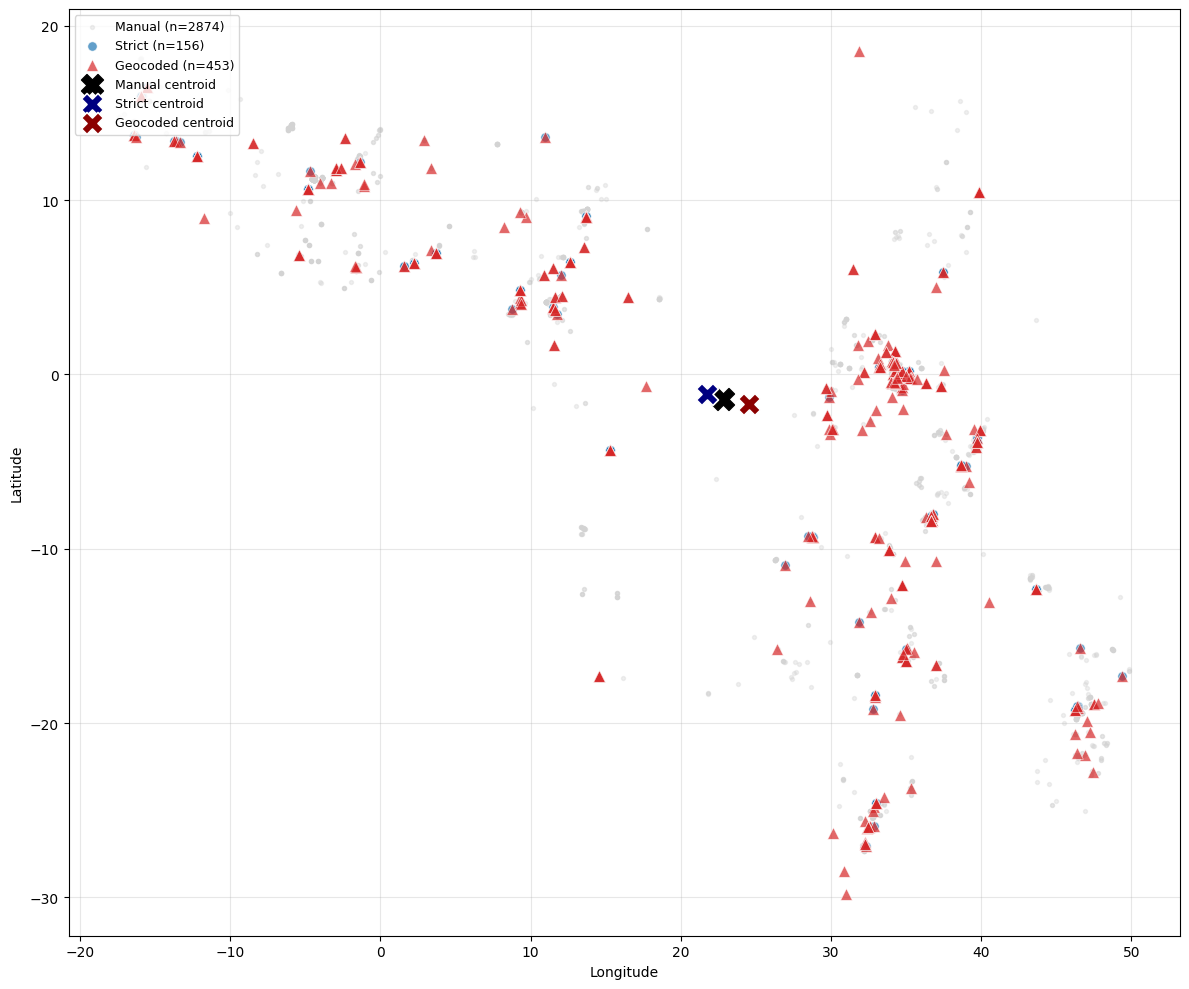

In [11]:
def plot_pipeline_overlay(strict, geo, manual_df, cols, manual_cols, out_path):
    fig, ax = plt.subplots(figsize=(12, 10))
    if manual_df is not None:
        ax.scatter(manual_df[manual_cols["longitude"]], manual_df[manual_cols["latitude"]],
                   s=8, alpha=0.35, c="lightgray",
                   label=f"Manual (n={len(manual_df)})", zorder=1)
    ax.scatter(strict[cols["longitude"]], strict[cols["latitude"]],
               s=45, alpha=0.7, c="tab:blue", edgecolors="white", linewidths=0.5,
               label=f"Strict (n={len(strict)})", marker="o", zorder=2)
    ax.scatter(geo[cols["longitude"]], geo[cols["latitude"]],
               s=70, alpha=0.7, c="tab:red", edgecolors="white", linewidths=0.5,
               label=f"Geocoded (n={len(geo)})", marker="^", zorder=3)
    if manual_df is not None:
        ax.scatter([manual_df[manual_cols["longitude"]].mean()],
                   [manual_df[manual_cols["latitude"]].mean()],
                   s=250, c="black", marker="X", zorder=4, label="Manual centroid")
    if not strict.empty:
        ax.scatter([strict[cols["longitude"]].mean()], [strict[cols["latitude"]].mean()],
                   s=250, c="navy", marker="X", edgecolors="white", linewidths=1.2,
                   zorder=4, label="Strict centroid")
    if not geo.empty:
        ax.scatter([geo[cols["longitude"]].mean()], [geo[cols["latitude"]].mean()],
                   s=250, c="darkred", marker="X", edgecolors="white", linewidths=1.2,
                   zorder=4, label="Geocoded centroid")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.grid(alpha=0.3)
    ax.legend(loc="upper left", fontsize=9)
    plt.tight_layout()
    plt.savefig(out_path, dpi=CONFIG["fig_dpi"])
    plt.show()


plot_pipeline_overlay(
    auto_strict, auto_geo, manual_raw,
    CONFIG["columns"], CONFIG["manual_columns"],
    os.path.join(CONFIG["paths"]["figs_dir"], "pipeline_overlay.png"),
)


## 8. Geocoding audit

In [12]:
def geocoding_audit(df_geo, cols, top_n=30):
    if "_geocoded" not in df_geo.columns:
        print("No geocoding metadata on this DataFrame.")
        return
    rescued = df_geo[df_geo["_geocoded"]]
    print(f"Rows rescued via geocoding: {len(rescued)}")
    if not rescued.empty:
        group_cols = [cols["location_name"], cols["country"]]
        if "_geocode_query_country" in rescued.columns:
            group_cols.append("_geocode_query_country")
        if "_geocode_display" in rescued.columns:
            group_cols.append("_geocode_display")
        summary = (rescued.groupby(group_cols, dropna=False)
                          .agg(n_rows=(cols["doc_id"], "size"),
                               lat=(cols["latitude"], "first"),
                               lon=(cols["longitude"], "first"))
                          .sort_values("n_rows", ascending=False)
                          .head(top_n))
        print(summary.to_string())
    rejected = df_geo.attrs.get("rejected_hits", [])
    if rejected:
        print(f"\nRejected geocoder hits (n={len(rejected)}):")
        rej_df = pd.DataFrame(rejected, columns=["name", "country", "reason"])
        rej_df = (rej_df.value_counts(["name", "country", "reason"])
                        .reset_index(name="count")
                        .sort_values("count", ascending=False)
                        .head(top_n))
        print(rej_df.to_string(index=False))


geocoding_audit(auto_geo, CONFIG["columns"])


Rows rescued via geocoding: 297
                                                                                                                                                                       n_rows        lat        lon
study_site       country      _geocode_query_country _geocode_display                                                                                                                              
Ahero            Kenya        NaN                    Ahero, Ahero ward, Nyando, Kisumu County, Kenya                                                                        9  -0.172461  34.919023
Bulambuli        Uganda       NaN                    Bulambuli, Eastern Region, Uganda                                                                                      8   1.349499  34.276095
Karonga          Malawi       NaN                    Karonga, Northern Region, Malawi, Malawi                                                                               7 -10.084747

## 9. Distribution plots (resistance / biting / resting by species)

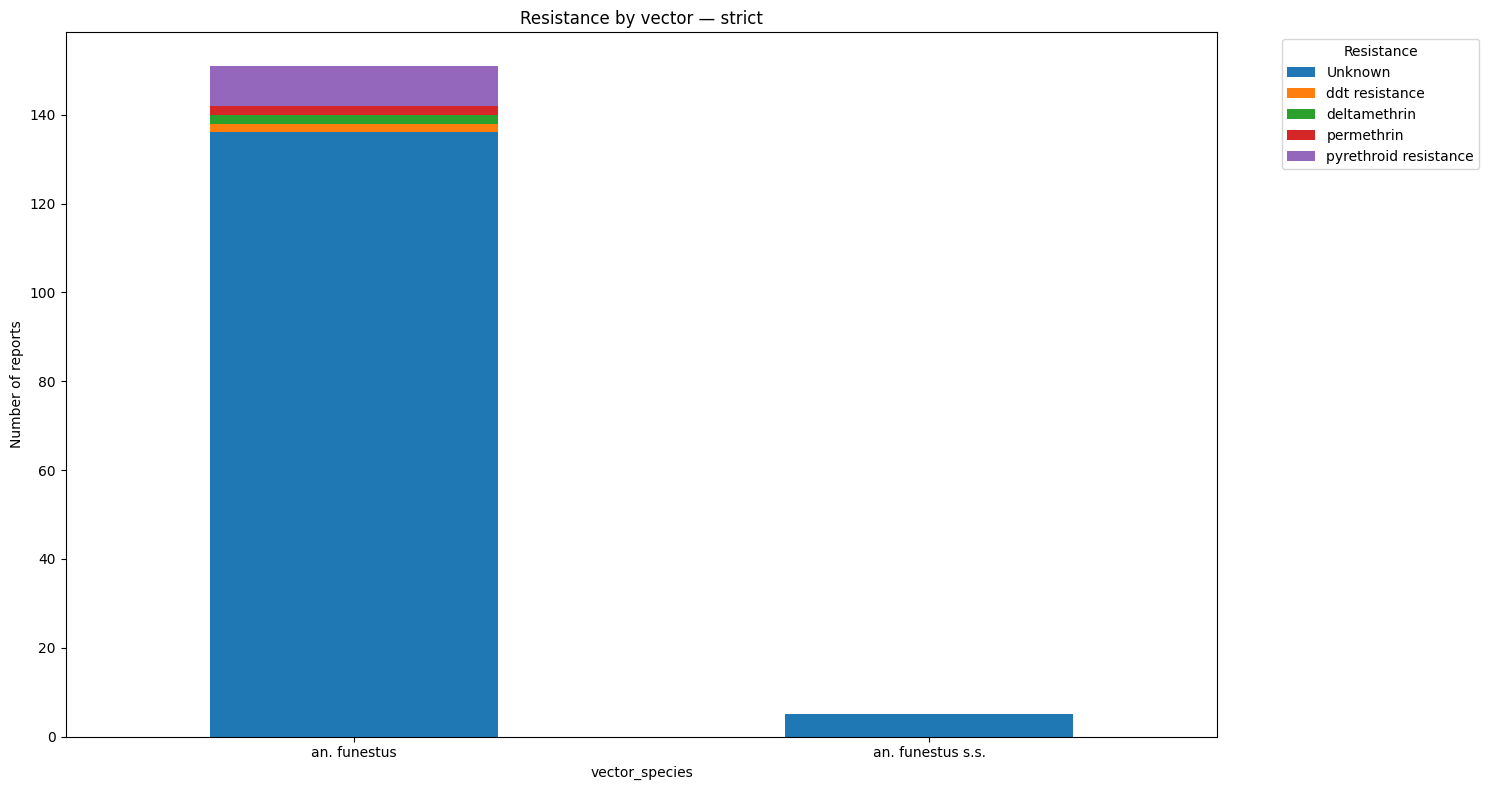

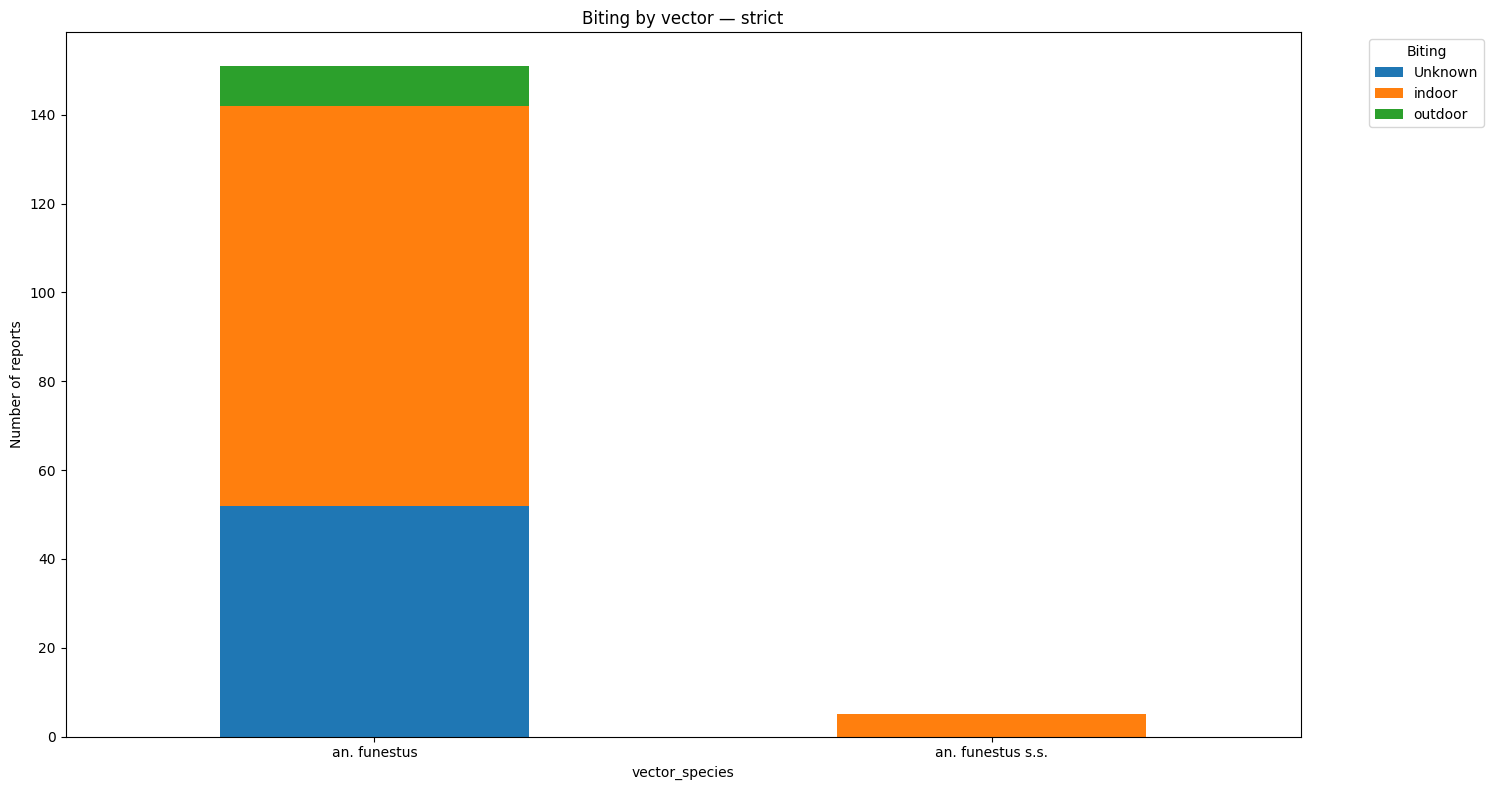

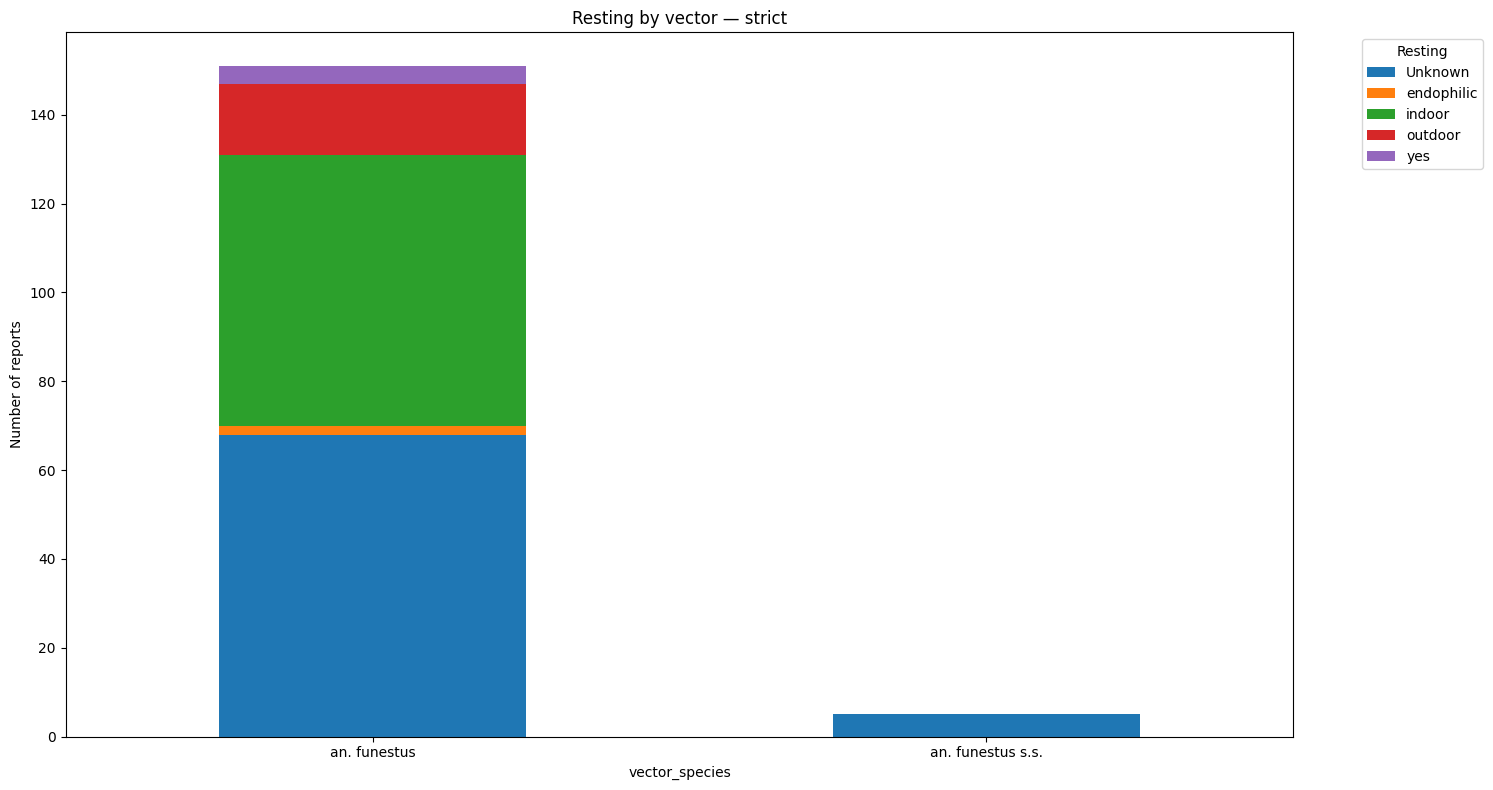

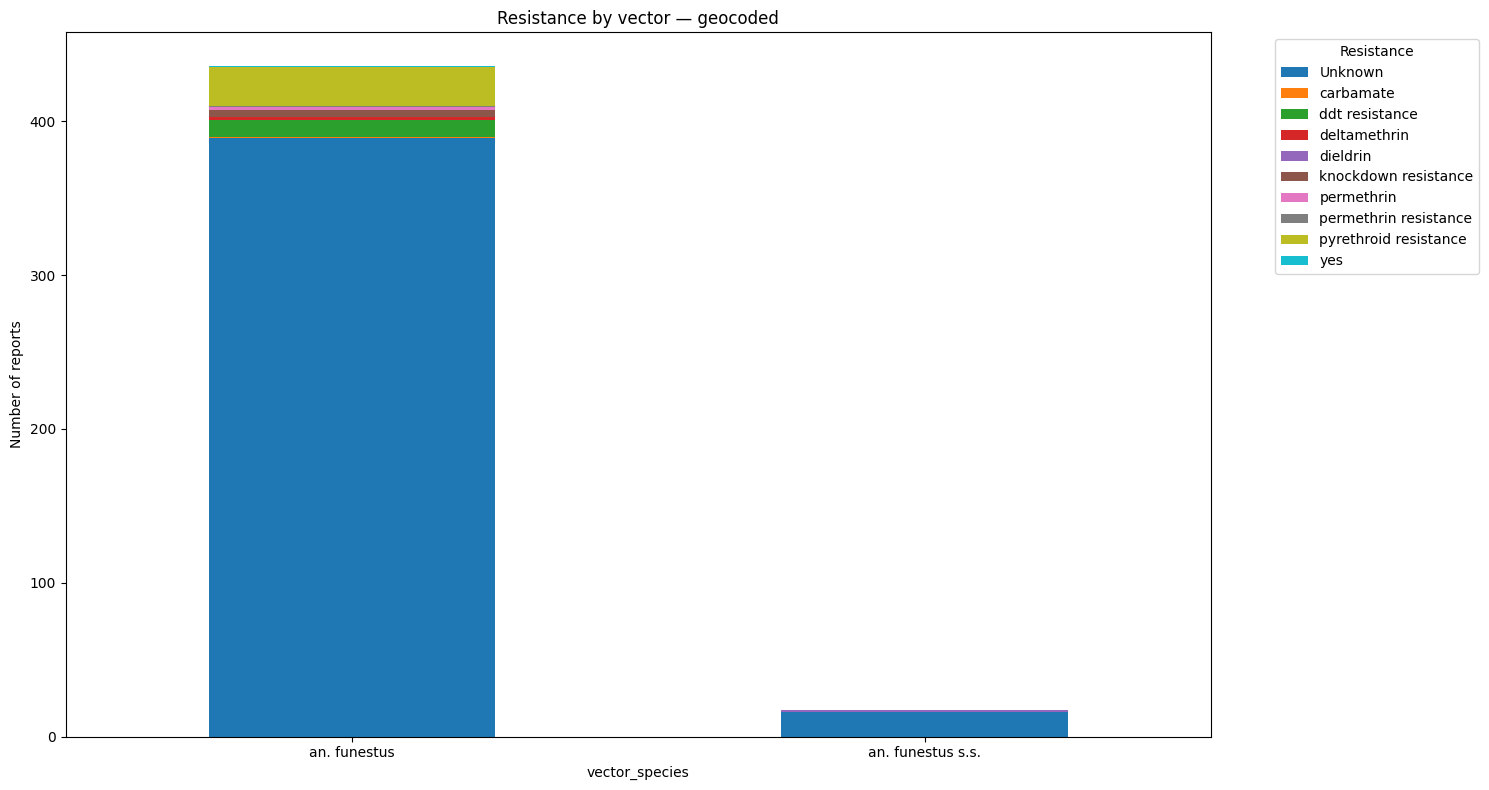

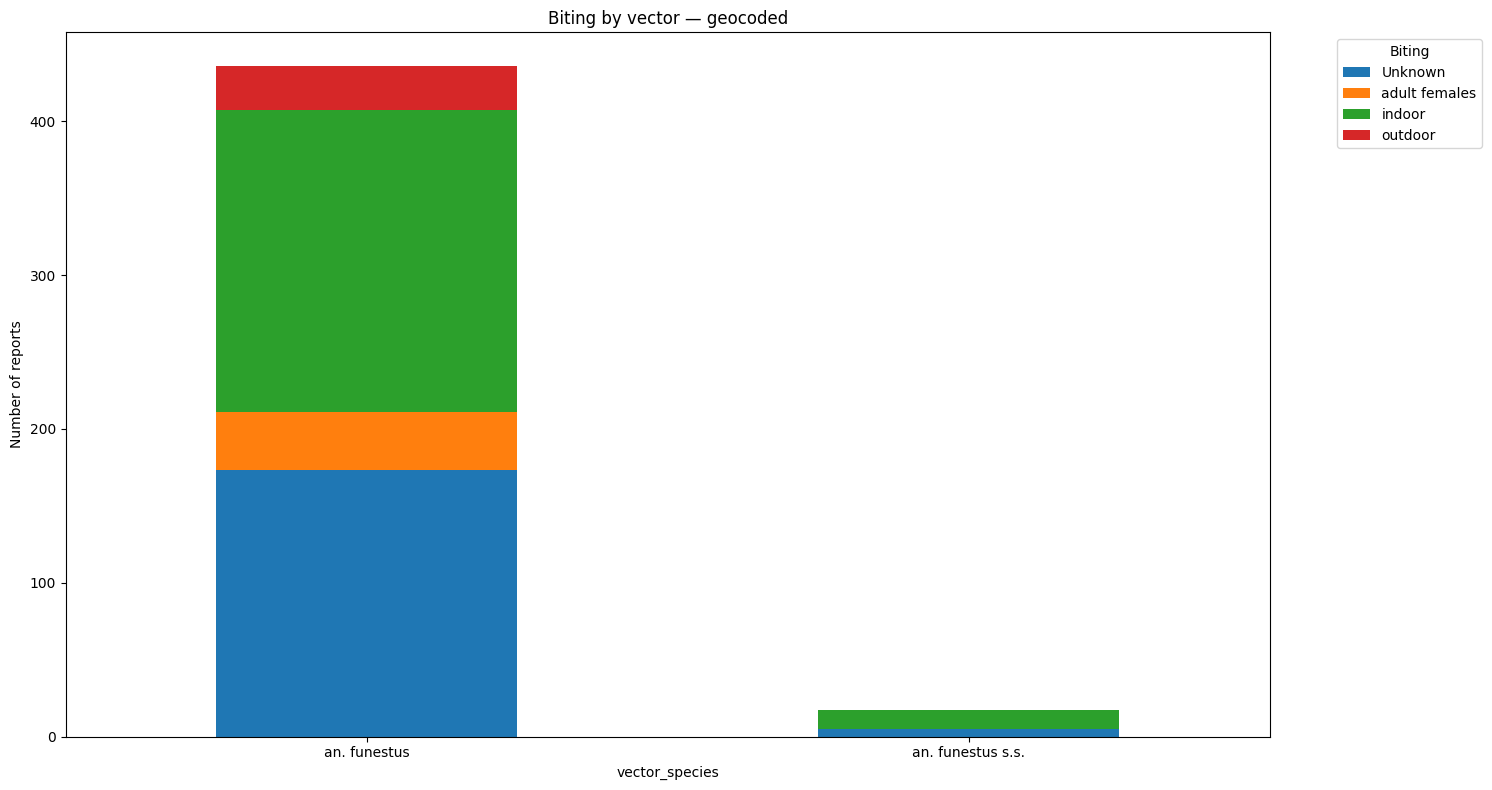

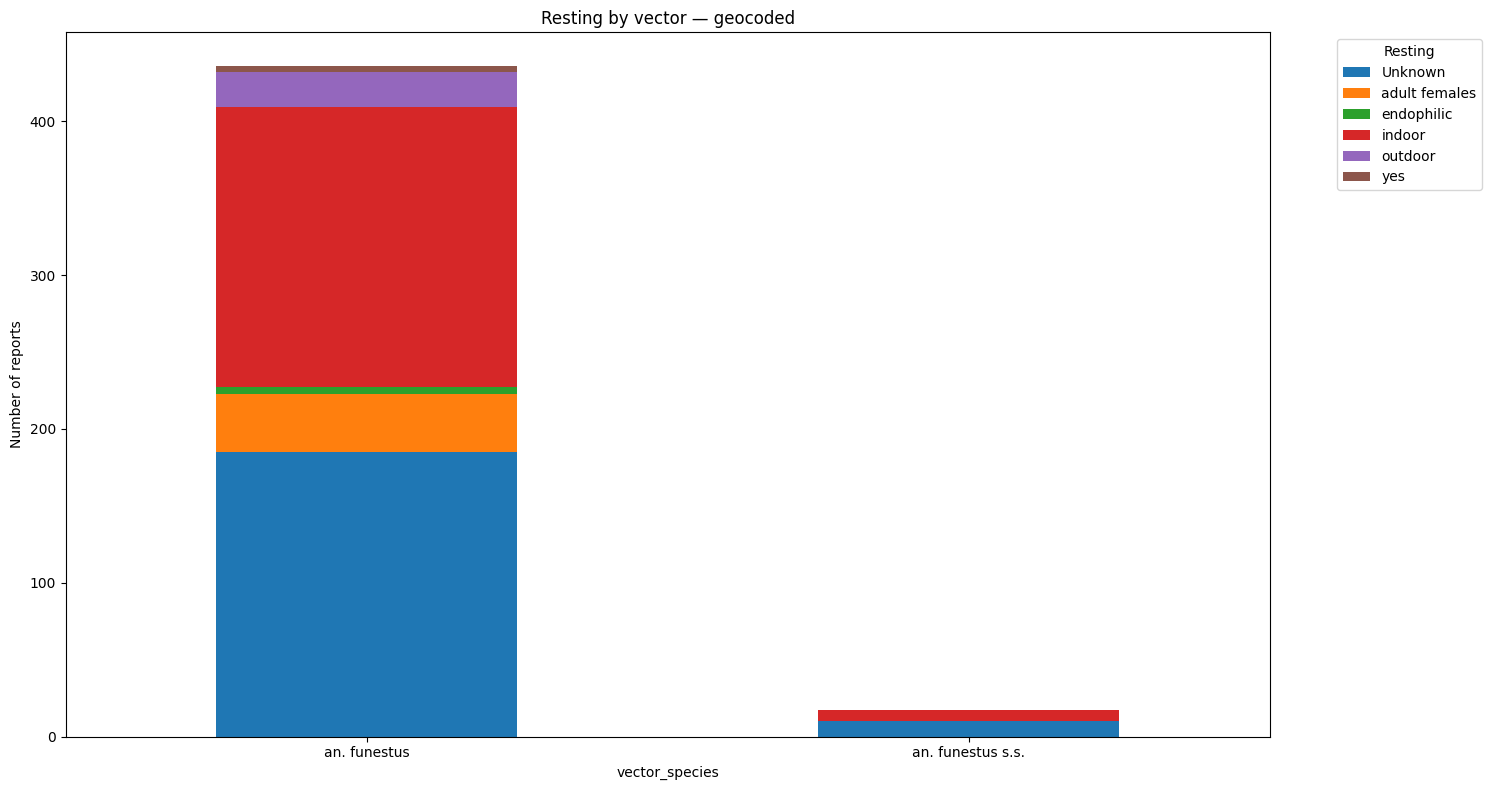

In [13]:
def plot_crosstab_by_species(df, species_col, value_col, out_path,
                             xlabel=None, legend_title=None, title=None):
    if species_col not in df.columns or value_col not in df.columns or df.empty:
        print(f"Skipping plot: missing {species_col!r} or {value_col!r}, or empty df")
        return None
    work = df[[species_col, value_col]].copy()
    work[value_col] = work[value_col].fillna("Unknown").astype(str)
    table = work.groupby([species_col, value_col]).size().unstack(fill_value=0)
    if table.empty:
        return table
    fig, ax = plt.subplots(figsize=(15, 8))
    table.plot(kind="bar", stacked=True, ax=ax)
    ax.set_xlabel(xlabel or species_col)
    ax.set_ylabel("Number of reports")
    if title:
        ax.set_title(title)
    ax.legend(title=legend_title or value_col, bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.xticks(rotation=0, ha="center")
    plt.tight_layout()
    plt.savefig(out_path, dpi=CONFIG["fig_dpi"])
    plt.show()
    return table


figs = CONFIG["paths"]["figs_dir"]
for pipeline_name, pipeline_df in [("strict", auto_strict), ("geocoded", auto_geo)]:
    for feature, out_name in [
        (c["resistance_type"],  "resistance"),
        (c["biting_location"], "biting"),
        (c["resting_location"],"resting"),
    ]:
        plot_crosstab_by_species(
            pipeline_df, c["vector_species"], feature,
            os.path.join(figs, f"{out_name}_by_vector_{pipeline_name}.png"),
            legend_title=out_name.capitalize(),
            title=f"{out_name.capitalize()} by vector — {pipeline_name}",
        )


## 10. Yearly distribution

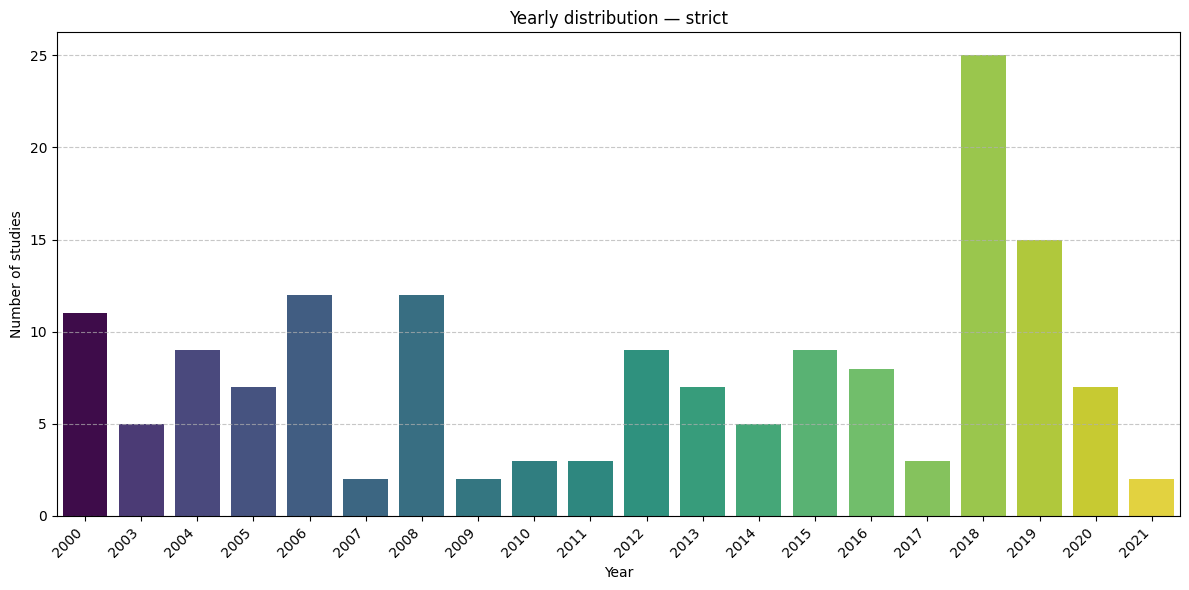

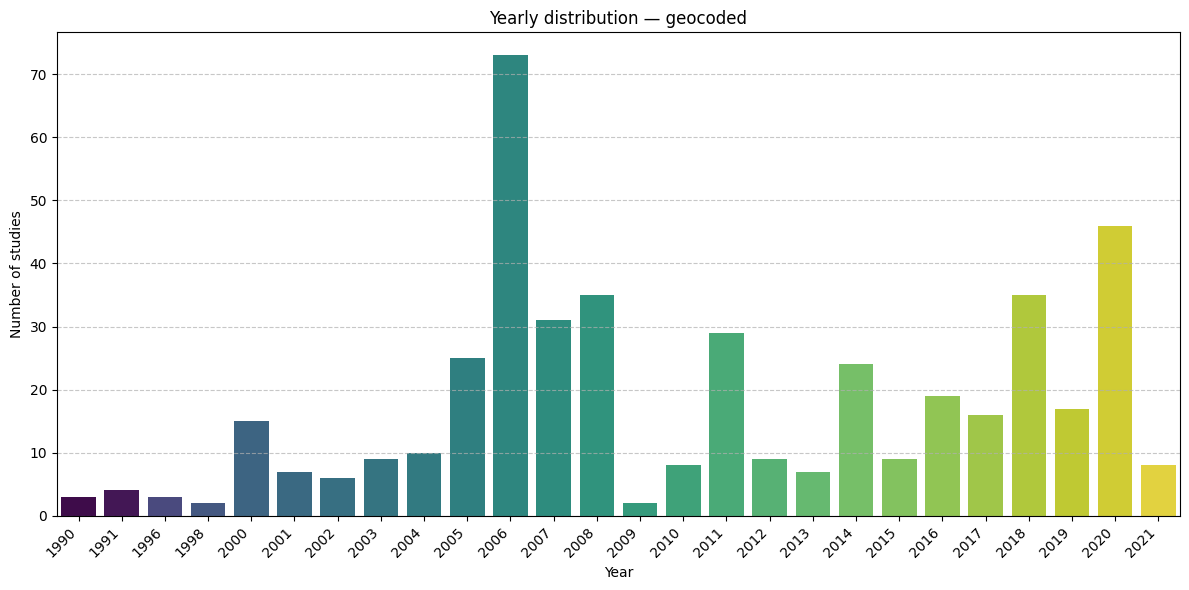

In [14]:
def plot_year_distribution(df, year_col, out_path, title=None):
    if year_col not in df.columns or df.empty:
        print(f"No {year_col!r} column or empty df")
        return
    years = pd.to_numeric(df[year_col], errors="coerce").dropna().astype(int)
    counts = years.value_counts().sort_index()
    if counts.empty:
        print("No valid years to plot")
        return
    plt.figure(figsize=(12, 6))
    sns.barplot(x=counts.index, y=counts.values, palette="viridis",
                hue=counts.index, legend=False)
    plt.xlabel("Year")
    plt.ylabel("Number of studies")
    if title:
        plt.title(title)
    plt.xticks(rotation=45, ha="right")
    plt.grid(axis="y", linestyle="--", alpha=0.7)
    plt.tight_layout()
    plt.savefig(out_path, dpi=CONFIG["fig_dpi"])
    plt.show()


for pipeline_name, pipeline_df in [("strict", auto_strict), ("geocoded", auto_geo)]:
    plot_year_distribution(
        pipeline_df, CONFIG["columns"]["year"],
        os.path.join(figs, f"yearly_distro_{pipeline_name}.png"),
        title=f"Yearly distribution — {pipeline_name}",
    )


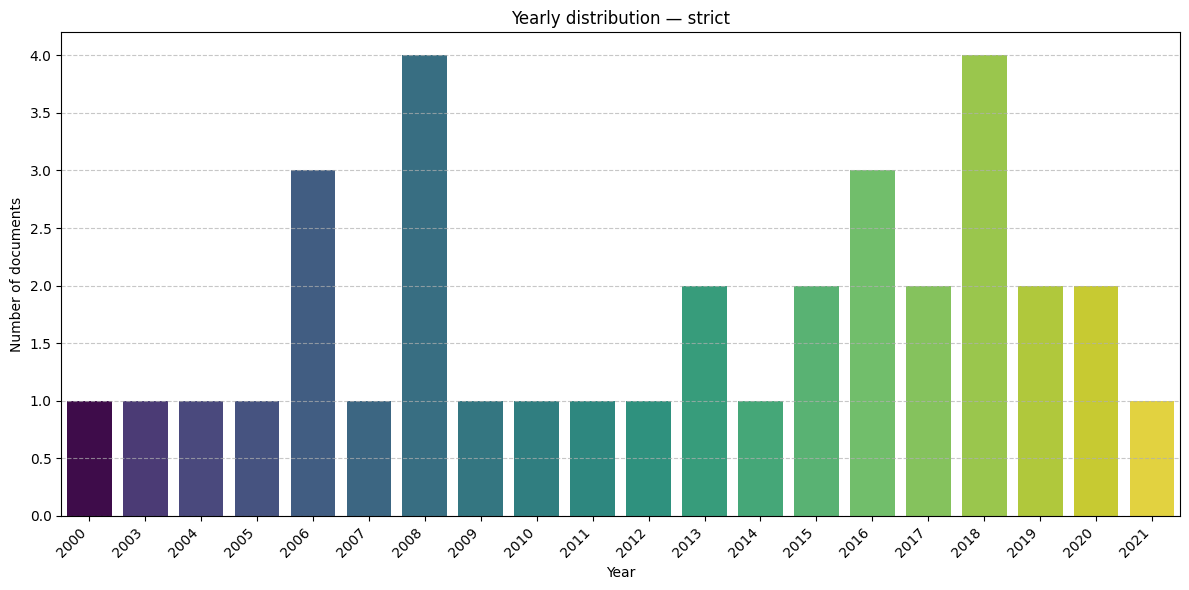

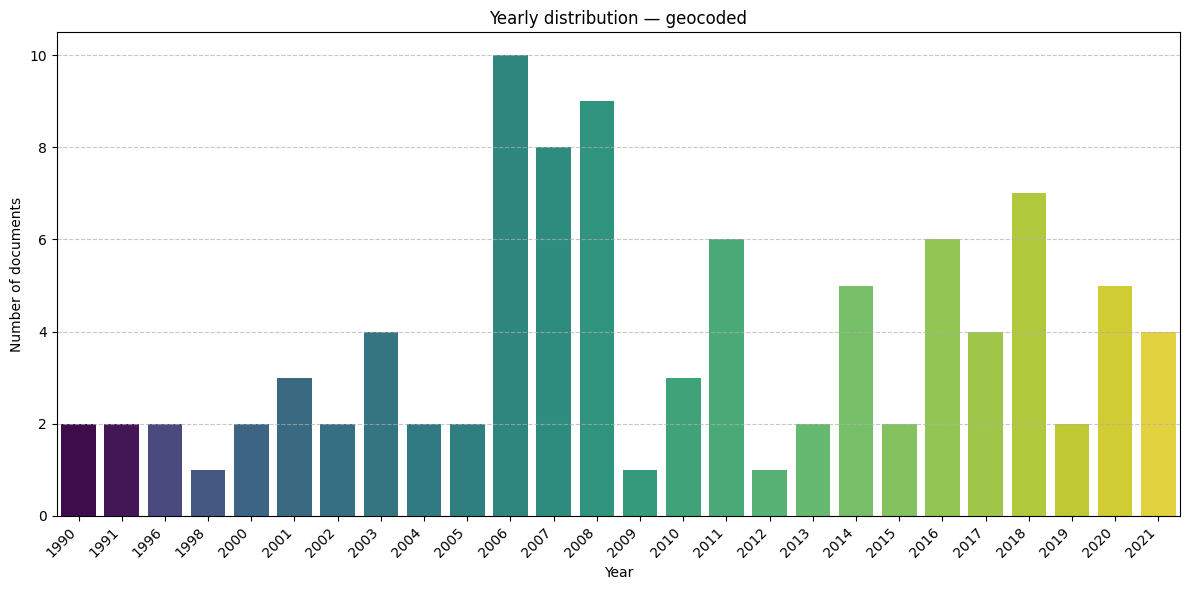

In [25]:
def plot_year_distribution(df, year_col, doc_id_col, out_path, title=None):
    if year_col not in df.columns or doc_id_col not in df.columns or df.empty:
        print(f"No {year_col!r} or {doc_id_col!r} column, or empty df")
        return
    work = df[[doc_id_col, year_col]].copy()
    work[year_col] = pd.to_numeric(work[year_col], errors="coerce")
    work = work.dropna(subset=[year_col])
    if work.empty:
        print("No valid years to plot")
        return
    work[year_col] = work[year_col].astype(int)
    doc_years = work.groupby(doc_id_col)[year_col].min()
    counts = doc_years.value_counts().sort_index()
    plt.figure(figsize=(12, 6))
    sns.barplot(x=counts.index, y=counts.values, palette="viridis",
                hue=counts.index, legend=False)
    plt.xlabel("Year")
    plt.ylabel("Number of documents")
    if title:
        plt.title(title)
    plt.xticks(rotation=45, ha="right")
    plt.grid(axis="y", linestyle="--", alpha=0.7)
    plt.tight_layout()
    plt.savefig(out_path, dpi=CONFIG["fig_dpi"])
    plt.show()


for pipeline_name, pipeline_df in [("strict", auto_strict), ("geocoded", auto_geo)]:
    plot_year_distribution(
        pipeline_df,
        CONFIG["columns"]["year"],
        CONFIG["columns"]["doc_id"],
        os.path.join(figs, f"yearly_distro_{pipeline_name}.png"),
        title=f"Yearly distribution — {pipeline_name}",
    )

In [26]:
def _category_doc_counts(df, value_col, doc_id_col):
    """
    Return a Series mapping each normalised category value to the number of
    unique documents that report it. A document is counted once per value,
    regardless of how many rows mention it.
    """
    if value_col not in df.columns or doc_id_col not in df.columns:
        return pd.Series(dtype=int)
    sub = df[[doc_id_col, value_col]].copy()
    sub[value_col] = (sub[value_col].astype(str).str.strip().str.lower())
    sub = sub[~sub[value_col].isin({"", "nan", "none", "n/a", "unknown"})]
    sub = sub.drop_duplicates()                    # one (doc, value) pair per row
    return (sub.groupby(value_col)[doc_id_col]
               .nunique()
               .sort_values(ascending=False))


def build_table4(df, cols, pipeline_label="geocoded"):
    """
    Reproduce Table 4 (bionomics + insecticide resistance summary) from a
    cleaned pipeline DataFrame. Counts are unique documents per category.
    """
    doc = cols["doc_id"]
    resting = _category_doc_counts(df, cols["resting_location"],  doc)
    biting  = _category_doc_counts(df, cols["biting_location"],   doc)
    ir      = _category_doc_counts(df, cols["resistance_type"],   doc)

    n = max(len(resting), len(biting), len(ir), 1)

    def _pad(series):
        items = list(series.items()) + [("", "")] * (n - len(series))
        return items[:n]

    rows = []
    for (r_lab, r_cnt), (b_lab, b_cnt), (i_lab, i_cnt) in zip(
            _pad(resting), _pad(biting), _pad(ir)):
        rows.append({
            "Resting location":   r_lab,
            "Studies (resting)":  r_cnt,
            "Biting location":    b_lab,
            "Studies (biting)":   b_cnt,
            "IR mechanism":       i_lab,
            "Studies (IR)":       i_cnt,
        })

    table = pd.DataFrame(rows)

    print("=" * 84)
    print(f"Table 4 — bionomics and IR summary ({pipeline_label})")
    print(f"  source rows: {len(df)}   unique documents: {df[doc].nunique()}")
    print("=" * 84)
    print(table.to_string(index=False))
    print()
    return table


def table4_to_latex(table, caption, label):
    """
    Emit a LaTeX fragment matching the manuscript layout. Merge the empty
    spacer cells into \\multicolumn{2}{c}{} so the table compiles cleanly.
    """
    def _cell(v):
        if v == "" or pd.isna(v):
            return ""
        return str(v)

    def _num(v):
        return "" if v == "" or pd.isna(v) else int(v)

    body_lines = []
    for _, r in table.iterrows():
        r_lab, r_cnt = _cell(r["Resting location"]), _num(r["Studies (resting)"])
        b_lab, b_cnt = _cell(r["Biting location"]),  _num(r["Studies (biting)"])
        i_lab, i_cnt = _cell(r["IR mechanism"]),     _num(r["Studies (IR)"])

        if r_lab == "" and b_lab == "" and i_lab == "":
            continue
        body_lines.append(
            f"{r_lab or ''} & {r_cnt or ''} & "
            f"{b_lab or ''} & {b_cnt or ''} & "
            f"{i_lab or ''} & {i_cnt or ''} \\\\"
        )

    body = "\n\\midrule\n".join(body_lines)
    return (
        "\\begin{table}[ht]\n"
        "\\centering\n"
        f"\\caption{{{caption}}}\n"
        f"\\label{{{label}}}\n"
        "\\small\n"
        "\\begin{tabular}{p{0.16\\linewidth}|p{0.10\\linewidth}|"
        "p{0.16\\linewidth}|p{0.10\\linewidth}|"
        "p{0.16\\linewidth}|p{0.10\\linewidth}}\n"
        "\\toprule\n"
        "\\multicolumn{2}{c|}{\\textbf{Bionomics}} & "
        "\\multicolumn{2}{c|}{\\textbf{Bionomics}} & "
        "\\multicolumn{2}{c}{\\textbf{Insecticide Resistance}} \\\\\n"
        "\\midrule\n"
        "\\textit{Resting location} & \\textit{n} & "
        "\\textit{Biting location} & \\textit{n} & "
        "\\textit{IR mechanism} & \\textit{n} \\\\\n"
        "\\midrule\n"
        f"{body}\n"
        "\\bottomrule\n"
        "\\end{tabular}\n"
        "\\end{table}\n"
    )


# ---- Build for each pipeline ------------------------------------------------
tbl4_geocoded = build_table4(auto_geo,    CONFIG["columns"], "geocoded")
tbl4_strict   = build_table4(auto_strict, CONFIG["columns"], "strict")

# ---- Optional: LaTeX output for the manuscript ------------------------------
latex_table4 = table4_to_latex(
    tbl4_geocoded,
    caption=("Summary of extracted bionomics and insecticide-resistance data "
             "with the automatic data extraction pipeline. Counts are the "
             "number of unique documents reporting each category."),
    label="tab:summary_bio_ir",
)
print(latex_table4)

# Optionally write it to disk
with open(os.path.join(CONFIG["paths"]["out_dir"], "table4.tex"), "w") as f:
    f.write(latex_table4)

Table 4 — bionomics and IR summary (geocoded)
  source rows: 453   unique documents: 98
Resting location Studies (resting) Biting location Studies (biting)          IR mechanism  Studies (IR)
          indoor                48          indoor               49 pyrethroid resistance             7
         outdoor                 4         outdoor               10        ddt resistance             2
   adult females                 1   adult females                1             carbamate             1
      endophilic                 1                                               dieldrin             1
             yes                 1                                           deltamethrin             1
                                                                     knockdown resistance             1
                                                                               permethrin             1
                                                                    permethrin r

## 11. Pipeline stage timing

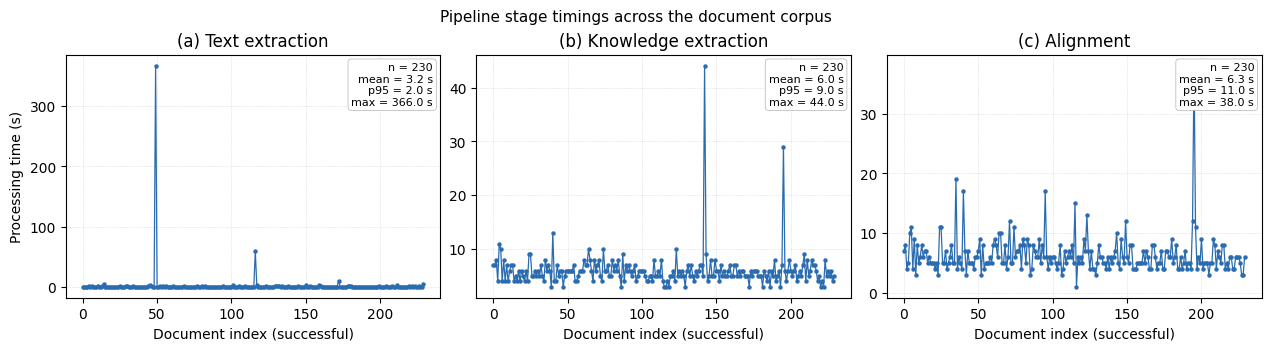

Saved figs/pipeline_stage_timings.png
Saved figs/pipeline_stage_timings.pdf

Timing summary


,Stage,Total,OK,Skipped,Failed,Mean (s),Median (s),P95 (s),Max (s)
0,Text extraction,230,230,0,0,3.16,1.0,2.0,366
1,Knowledge extraction,230,230,0,0,6.01,6.0,9.0,44
2,Alignment,230,230,0,0,6.31,6.0,11.0,38



Triples summary


,Stage,Triples mean,Triples median,Triples min,Triples max
0,Knowledge extraction,30.7,24.0,0,373
1,Alignment,29.1,23.0,0,372


In [16]:
def _read_stage_log(log_path: str) -> pd.DataFrame:
    with open(log_path, "r", encoding="utf-8") as f:
        first_line = f.readline().strip()
    if first_line.startswith("name,"):
        return pd.read_csv(log_path, keep_default_na=False, na_values=[""])
    return pd.read_csv(log_path, header=None, names=["name", "ts"])


def _stage_stats(log_path: str, stage_label: str) -> dict:
    stub = {
        "stage": stage_label, "n_total": 0, "n_ok": 0,
        "n_skipped": 0, "n_failed": 0,
        "mean_s": float("nan"), "median_s": float("nan"),
        "p95_s": float("nan"), "max_s": float("nan"),
        "triples_mean": float("nan"), "triples_median": float("nan"),
        "triples_min": float("nan"), "triples_max": float("nan"),
        "_ts_series": pd.Series(dtype=float),
    }
    if not os.path.exists(log_path):
        return stub
    df = _read_stage_log(log_path)
    if df.empty:
        return stub
    n_total = len(df)
    n_skipped = n_failed = 0
    if "status" in df.columns:
        n_skipped = int((df["status"] == "skipped").sum())
        n_failed = int((df["status"] == "failed").sum())
        df = df[df["status"] == "ok"].copy()
    df["ts"] = pd.to_numeric(df["ts"], errors="coerce")
    ts = df["ts"].dropna().reset_index(drop=True)
    stats = {
        "stage": stage_label, "n_total": n_total, "n_ok": int(len(ts)),
        "n_skipped": n_skipped, "n_failed": n_failed,
        "mean_s": ts.mean() if not ts.empty else float("nan"),
        "median_s": ts.median() if not ts.empty else float("nan"),
        "p95_s": ts.quantile(0.95) if not ts.empty else float("nan"),
        "max_s": ts.max() if not ts.empty else float("nan"),
        "_ts_series": ts,
    }
    nt = (pd.to_numeric(df["n_triples"], errors="coerce").dropna()
          if "n_triples" in df.columns else pd.Series(dtype=float))
    stats.update({
        "triples_mean": nt.mean() if not nt.empty else float("nan"),
        "triples_median": nt.median() if not nt.empty else float("nan"),
        "triples_min": nt.min() if not nt.empty else float("nan"),
        "triples_max": nt.max() if not nt.empty else float("nan"),
    })
    return stats


def plot_stage_logs_panel(
    stage_specs: list,
    out_dir: str,
    dpi: int = 600,
    panel_size: tuple = (4.2, 3.4),
    suptitle: str = None,
    paper_style: bool = False,
):
    if paper_style:
        plt.rcParams.update({
            "font.family": "serif", "font.size": 9,
            "axes.labelsize": 9, "axes.titlesize": 10,
            "xtick.labelsize": 8, "ytick.labelsize": 8,
            "legend.fontsize": 8, "pdf.fonttype": 42, "ps.fonttype": 42,
        })
    stats_list = []
    for label, fname in stage_specs:
        p = os.path.join(CONFIG["paths"]["logs_dir"], fname)
        s = _stage_stats(p, label)
        if s["n_total"] == 0:
            print(f"Log not found or empty: {p}")
        stats_list.append(s)
    n = len(stage_specs)
    fig, axes = plt.subplots(1, n,
                             figsize=(panel_size[0] * n, panel_size[1]),
                             constrained_layout=True)
    if n == 1:
        axes = [axes]
    letters = "abcdefghij"
    for i, (ax, s) in enumerate(zip(axes, stats_list)):
        ts = s["_ts_series"]
        if ts.empty:
            ax.text(0.5, 0.5, "no data", ha="center", va="center",
                    transform=ax.transAxes, fontsize=9)
            ax.set_xticks([]); ax.set_yticks([])
        else:
            ax.plot(range(len(ts)), ts.values,
                    marker="o", markersize=2.2, linewidth=0.9,
                    color="#2b6cb0")
            ax.set_xlabel("Document index (successful)")
            if i == 0:
                ax.set_ylabel("Processing time (s)")
            ax.grid(True, linestyle=":", linewidth=0.5, alpha=0.6)
            ax.set_axisbelow(True)
            ax.text(0.98, 0.97,
                    f"n = {s['n_ok']}\n"
                    f"mean = {s['mean_s']:.1f} s\n"
                    f"p95 = {s['p95_s']:.1f} s\n"
                    f"max = {s['max_s']:.1f} s",
                    transform=ax.transAxes, ha="right", va="top", fontsize=8,
                    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="0.7", lw=0.5))
        ax.set_title(f"({letters[i]}) {s['stage']}")
    if suptitle:
        fig.suptitle(suptitle, fontsize=11)
    os.makedirs(out_dir, exist_ok=True)
    png_path = os.path.join(out_dir, "pipeline_stage_timings.png")
    pdf_path = os.path.join(out_dir, "pipeline_stage_timings.pdf")
    fig.savefig(png_path, dpi=dpi, bbox_inches="tight")
    fig.savefig(pdf_path, bbox_inches="tight")
    plt.show()
    print(f"Saved {png_path}\nSaved {pdf_path}")
    timing_rows, triples_rows = [], []
    for s in stats_list:
        timing_rows.append({
            "Stage": s["stage"], "Total": s["n_total"], "OK": s["n_ok"],
            "Skipped": s["n_skipped"], "Failed": s["n_failed"],
            "Mean (s)":   round(s["mean_s"], 2)   if pd.notna(s["mean_s"])   else "",
            "Median (s)": round(s["median_s"], 2) if pd.notna(s["median_s"]) else "",
            "P95 (s)":    round(s["p95_s"], 2)    if pd.notna(s["p95_s"])    else "",
            "Max (s)":    round(s["max_s"], 2)    if pd.notna(s["max_s"])    else "",
        })
        if pd.notna(s["triples_mean"]):
            triples_rows.append({
                "Stage": s["stage"],
                "Triples mean":   round(s["triples_mean"], 1),
                "Triples median": round(s["triples_median"], 0),
                "Triples min":    round(s["triples_min"], 0),
                "Triples max":    round(s["triples_max"], 0),
            })
    timing_table = pd.DataFrame(timing_rows)
    triples_table = pd.DataFrame(triples_rows)
    timing_table.to_csv(os.path.join(out_dir, "pipeline_stage_timings_summary.csv"), index=False)
    if not triples_table.empty:
        triples_table.to_csv(os.path.join(out_dir, "pipeline_stage_triples_summary.csv"), index=False)
    return timing_table, triples_table


stage_specs = [
    ("Text extraction",      "text_extraction_logs.csv"),
    ("Knowledge extraction", "knowledge_extraction_logs.csv"),
    ("Alignment",            "aligned_extraction_logs.csv"),
]

timing_table, triples_table = plot_stage_logs_panel(
    stage_specs,
    out_dir=CONFIG["paths"]["figs_dir"],
    suptitle="Pipeline stage timings across the document corpus",
    paper_style=False,
)

print("\nTiming summary")
display(timing_table)
print("\nTriples summary")
display(triples_table)


## 12. Per-document quality summary

In [17]:
def per_document_summary(df, doc_id_col, label="", top_n=30):
    if doc_id_col not in df.columns or df.empty:
        print(f"[{label}] missing {doc_id_col!r} or empty df")
        return None
    counts = df[doc_id_col].value_counts()
    print(f"[{label}] Docs: {len(counts)}, rows: {counts.sum()}, "
          f"mean rows/doc: {counts.mean():.1f}, median: {counts.median():.0f}")
    return counts.head(top_n)


_ = per_document_summary(auto_strict, c["doc_id"], label="strict")
_ = per_document_summary(auto_geo,    c["doc_id"], label="geocoded")


[strict] Docs: 35, rows: 156, mean rows/doc: 4.5, median: 3
[geocoded] Docs: 98, rows: 453, mean rows/doc: 4.6, median: 3


## 13. Funnel diagnostics

In [18]:
def funnel_report(raw, cols):
    doc = cols["doc_id"]
    species = cols["vector_species"]
    print(f"0. Raw extracted CSV:               {raw[doc].nunique()} docs, {len(raw)} rows")
    step1 = raw.copy()
    if species in step1.columns:
        step1[species] = step1[species].apply(uniform_vector_name)
        allowed = {s.lower() for s in CONFIG["vector_species_filter"]}
        step1 = step1[step1[species].isin(allowed)]
    print(f"1. After species filter:            {step1[doc].nunique()} docs, {len(step1)} rows")
    step2 = step1.copy()
    step2["_lat"] = step2[cols["latitude"]].apply(
        lambda x: parse_coordinate_string(x, kind="lat")) if cols["latitude"] in step2.columns else np.nan
    step2["_lon"] = step2[cols["longitude"]].apply(
        lambda x: parse_coordinate_string(x, kind="lon")) if cols["longitude"] in step2.columns else np.nan
    both_ok = step2["_lat"].notna() & step2["_lon"].notna()
    print(f"2. Rows with both coords valid:     {int(both_ok.sum())} rows "
          f"({step2.loc[both_ok, doc].nunique()} docs)")
    step3 = step2[both_ok]
    print(f"3. Surviving after strict filter:   {step3[doc].nunique()} docs, {len(step3)} rows")
    killed_by_species = set(raw[doc]) - set(step1[doc])
    killed_by_coords  = set(step1[doc]) - set(step3[doc])
    print(f"\nDocs dropped purely by species filter:        {len(killed_by_species)}")
    print(f"Target-species docs dropped for missing coords: {len(killed_by_coords)}")
    if species in raw.columns:
        print("\nTop species in the raw CSV (before filtering):")
        print(raw[species].value_counts(dropna=False).head(20).to_string())


funnel_report(auto_raw, CONFIG["columns"])


0. Raw extracted CSV:               230 docs, 1456 rows
1. After species filter:            114 docs, 583 rows
2. Rows with both coords valid:     156 rows (35 docs)
3. Surviving after strict filter:   35 docs, 156 rows

Docs dropped purely by species filter:        116
Target-species docs dropped for missing coords: 79

Top species in the raw CSV (before filtering):
vector_species
Anopheles funestus             550
Pseudoficalbia mashonaensis    105
Anopheles arabiensis            96
NaN                             91
Anopheles gambiae               68
Anopheles gambiae s.s.          55
Anopheles rivulorum             45
Anopheles gambiae s.l.          38
Anopheles nili                  38
Culex quinquefasciatus          36
m                               35
Anopheles funestus s.s.         33
Anopheles parensis              30
Anopheles vaneedeni             27
Anopheles gambiae complex       25
Anopheles melas                 20
Anopheles mascarensis           20
Anopheles coluzzii  

In [19]:
# --- Ad-hoc Nominatim probe ---
# import requests
# for q in ["Yala River, nan", "Yala River, Kenya", "Pitoa, Cameroon", "Yala"]:
#     r = requests.get("https://nominatim.openstreetmap.org/search",
#                      params={"q": q, "format": "json", "limit": 1},
#                      headers={"User-Agent": CONFIG["geocoder"]["user_agent"]},
#                      timeout=15)
#     print(f"{q!r}: {r.status_code} -> {len(r.json())} result(s)")


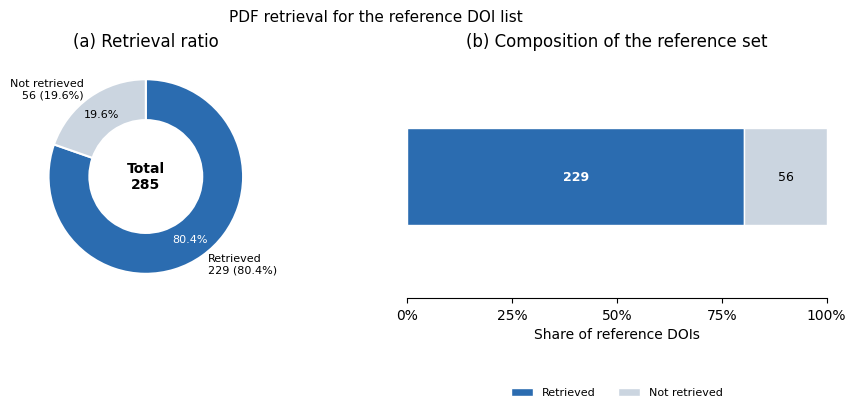

Saved figs/pdf_retrieval_ratio.png
Saved figs/pdf_retrieval_ratio.pdf
Saved figs/pdf_retrieval_summary.csv

Retrieval summary


,Reference DOIs,Retrieved,Retrieved (%),Not retrieved,Not retrieved (%)
0,285,229,80.4,56,19.6


In [20]:
# ---------------------------------------------------------------------------
# PDF retrieval assessment
# ---------------------------------------------------------------------------
from pathlib import Path


def assess_pdf_retrieval(pdf_folder, doi_csv, doi_column="doi",
                         out_dir=None, dpi=600, paper_style=False):
    if out_dir is None:
        out_dir = CONFIG["paths"]["figs_dir"]
    os.makedirs(out_dir, exist_ok=True)
    pdf_root = Path(pdf_folder)
    if not pdf_root.exists():
        raise FileNotFoundError(f"PDF folder not found: {pdf_root}")
    retrieved_stems = {f.stem for f in pdf_root.rglob("*.pdf")}
    dois_df = pd.read_csv(doi_csv)
    if doi_column not in dois_df.columns:
        raise KeyError(f"Column {doi_column!r} not in {doi_csv}")
    downloaded, missing = [], []
    for raw in dois_df[doi_column].dropna():
        doi = str(raw).strip()
        if not doi:
            continue
        (downloaded if doi.replace("/", "_") in retrieved_stems
         else missing).append(doi)
    n_retrieved, n_missing = len(downloaded), len(missing)
    total = n_retrieved + n_missing
    if total == 0:
        raise ValueError("No DOIs to assess.")
    pct_retrieved = n_retrieved / total
    pct_missing = n_missing / total
    if paper_style:
        plt.rcParams.update({
            "font.family": "serif", "font.size": 9,
            "axes.labelsize": 9, "axes.titlesize": 10,
            "xtick.labelsize": 8, "ytick.labelsize": 8,
            "legend.fontsize": 8, "pdf.fonttype": 42, "ps.fonttype": 42,
        })
    fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.0),
                             gridspec_kw={"width_ratios": [1.15, 1.0]},
                             constrained_layout=True)
    c_hit, c_miss = "#2b6cb0", "#cbd5e0"
    ax = axes[0]
    sizes = [n_retrieved, n_missing]
    labels = [f"Retrieved\n{n_retrieved} ({pct_retrieved:.1%})",
              f"Not retrieved\n{n_missing} ({pct_missing:.1%})"]
    wedges, texts, autotexts = ax.pie(
        sizes, labels=labels, colors=[c_hit, c_miss], autopct="%1.1f%%",
        startangle=90, counterclock=False, textprops={"fontsize": 8},
        wedgeprops={"width": 0.42, "edgecolor": "white", "linewidth": 1.5},
        pctdistance=0.79)
    for t in autotexts:
        t.set_fontsize(8)
        t.set_color("white" if t.get_text().startswith(f"{pct_retrieved*100:.1f}") else "black")
    ax.text(0, 0, f"Total\n{total}", ha="center", va="center",
            fontsize=10, fontweight="bold")
    ax.set_title("(a) Retrieval ratio")
    ax.set_aspect("equal")
    ax = axes[1]
    bar_h = 0.4
    ax.barh([0], [pct_retrieved], height=bar_h, color=c_hit,
            edgecolor="white", linewidth=1.0, label="Retrieved")
    ax.barh([0], [pct_missing], left=[pct_retrieved], height=bar_h, color=c_miss,
            edgecolor="white", linewidth=1.0, label="Not retrieved")
    if pct_retrieved > 0.08:
        ax.text(pct_retrieved / 2, 0, f"{n_retrieved}", ha="center",
                va="center", fontsize=9, color="white", fontweight="bold")
    if pct_missing > 0.08:
        ax.text(pct_retrieved + pct_missing / 2, 0, f"{n_missing}",
                ha="center", va="center", fontsize=9, color="black")
    ax.set_xlim(0, 1); ax.set_ylim(-0.5, 0.5)
    ax.set_yticks([])
    ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
    ax.set_xticklabels(["0%", "25%", "50%", "75%", "100%"])
    ax.set_xlabel("Share of reference DOIs")
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.45),
              ncol=2, frameon=False, fontsize=8)
    ax.set_title("(b) Composition of the reference set")
    for spine in ("top", "right", "left"):
        ax.spines[spine].set_visible(False)
    fig.suptitle("PDF retrieval for the reference DOI list", fontsize=11)
    png_path = os.path.join(out_dir, "pdf_retrieval_ratio.png")
    pdf_path = os.path.join(out_dir, "pdf_retrieval_ratio.pdf")
    fig.savefig(png_path, dpi=dpi, bbox_inches="tight")
    fig.savefig(pdf_path, bbox_inches="tight")
    plt.show()
    print(f"Saved {png_path}\nSaved {pdf_path}")
    summary = pd.DataFrame([{
        "Reference DOIs":    total,
        "Retrieved":         n_retrieved,
        "Retrieved (%)":     round(100 * pct_retrieved, 1),
        "Not retrieved":     n_missing,
        "Not retrieved (%)": round(100 * pct_missing, 1),
    }])
    summary_path = os.path.join(out_dir, "pdf_retrieval_summary.csv")
    summary.to_csv(summary_path, index=False)
    print(f"Saved {summary_path}")
    return summary, downloaded, missing


retrieval_summary, downloaded_dois, missing_dois = assess_pdf_retrieval(
    pdf_folder=CONFIG["paths"]["source_pdfs"],
    doi_csv=CONFIG["paths"]["doi_csv"],
    doi_column=CONFIG["paths"]["doi_column"],
    out_dir=CONFIG["paths"]["figs_dir"],
    paper_style=False,
)
print("\nRetrieval summary")
display(retrieval_summary)


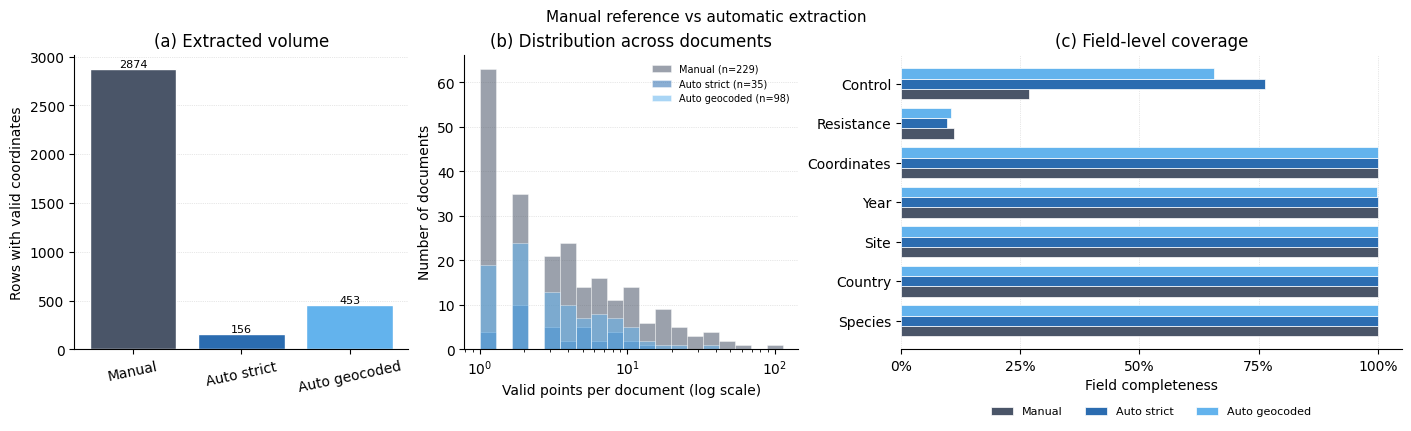

Saved figs/manual_vs_auto_comparison.png
Saved figs/manual_vs_auto_comparison.pdf
Note: 1291 manual rows could not be mapped to a doc_id.

Volume summary


,Source,Docs (mapped),Valid points,Mean / doc,Median / doc,Max / doc
0,Manual,229,2874,6.9,3.0,114
1,Auto strict,35,156,4.5,3.0,14
2,Auto geocoded,98,453,4.6,3.0,38



Document coverage


,Manual only,Auto only,Both,Union
0,194,0,35,229



Field completeness


,Field,Manual,Auto strict,Auto geocoded
0,Species,100.0%,100.0%,100.0%
1,Country,100.0%,100.0%,100.0%
2,Site,100.0%,100.0%,100.0%
3,Year,100.0%,100.0%,99.8%
4,Coordinates,100.0%,100.0%,100.0%
5,Resistance,11.2%,9.6%,10.6%
6,Control,26.8%,76.3%,65.6%


In [21]:
# ---------------------------------------------------------------------------
# Manual reference vs automatic pipelines — per-document comparison
# ---------------------------------------------------------------------------
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path


def _resolve_manual_doc_ids(manual_df, manual_cols, mapping_path):
    doc_col = manual_cols.get("doc_id")
    doi_col = manual_cols.get("doi")
    if doc_col and doc_col in manual_df.columns:
        return manual_df[doc_col].astype(str)
    if doi_col and doi_col in manual_df.columns and mapping_path and os.path.exists(mapping_path):
        m = pd.read_csv(mapping_path)
        lookup = {str(r.iloc[0]).strip().replace("/", "_").lower(): str(r.iloc[1]).strip()
                  for _, r in m.iterrows()}
        return manual_df[doi_col].apply(
            lambda v: None if pd.isna(v)
            else lookup.get(str(v).strip().replace("/", "_").lower()))
    return pd.Series([None] * len(manual_df), index=manual_df.index)


def _completeness(df, column):
    if column is None or column not in df.columns or len(df) == 0:
        return np.nan
    s = df[column]
    if s.dtype == object:
        return (s.astype(str).str.strip()
                 .replace({"": np.nan, "nan": np.nan, "none": np.nan, "None": np.nan})
                 .notna().mean())
    return s.notna().mean()


def _valid_coord_count(df, lat_col, lon_col):
    if lat_col not in df.columns or lon_col not in df.columns:
        return 0
    lat = pd.to_numeric(df[lat_col], errors="coerce")
    lon = pd.to_numeric(df[lon_col], errors="coerce")
    return int((lat.between(LAT_MIN, LAT_MAX) & lon.between(LON_MIN, LON_MAX)).sum())


def compare_manual_auto(manual_df, auto_strict, auto_geo, cols, manual_cols,
                        mapping_path=None, out_dir=None, dpi=600,
                        paper_style=False,
                        suptitle="Manual reference vs automatic extraction"):
    if out_dir is None:
        out_dir = CONFIG["paths"]["figs_dir"]
    os.makedirs(out_dir, exist_ok=True)
    if paper_style:
        plt.rcParams.update({
            "font.family": "serif", "font.size": 9,
            "axes.labelsize": 9, "axes.titlesize": 10,
            "xtick.labelsize": 8, "ytick.labelsize": 8,
            "legend.fontsize": 8, "pdf.fonttype": 42, "ps.fonttype": 42,
        })

    mapping_exists = bool(mapping_path) and Path(mapping_path).exists()
    if not mapping_exists:
        print("=" * 74)
        print("pdf_mappings.csv NOT FOUND")
        print(f"  expected at : {mapping_path}")
        print("  impact      : coverage + panel (b) manual series will be empty")
        print("  unaffected  : panels (a) volume and (c) completeness")
        print("  fix         : run section-1 cell first")
        print("=" * 74)

    manual = manual_df.copy()
    manual["_doc_id"] = _resolve_manual_doc_ids(manual, manual_cols, mapping_path)
    n_unmapped = int(manual["_doc_id"].isna().sum())
    mapping_available = manual["_doc_id"].notna().any()

    doc_col = cols["doc_id"]
    m_lat = manual_cols.get("latitude", "latitude_1")
    m_lon = manual_cols.get("longitude", "longitude_1")

    manual_valid_count = _valid_coord_count(manual, m_lat, m_lon)
    strict_valid_count = _valid_coord_count(auto_strict, cols["latitude"], cols["longitude"])
    geo_valid_count    = _valid_coord_count(auto_geo,    cols["latitude"], cols["longitude"])

    manual_docs_series = (manual.dropna(subset=["_doc_id"]).groupby("_doc_id").size()
                          if mapping_available else pd.Series(dtype=int))
    strict_docs_series = auto_strict.groupby(doc_col).size()
    geo_docs_series    = auto_geo.groupby(doc_col).size()
    sources = {"Manual": manual_docs_series,
               "Auto strict": strict_docs_series,
               "Auto geocoded": geo_docs_series}

    def _stats(series):
        if series.empty:
            return 0, 0.0, 0.0, 0
        return (int(series.size), round(series.mean(), 1),
                round(series.median(), 0), int(series.max()))

    m_docs, m_mean, m_med, m_max = _stats(manual_docs_series)
    s_docs, s_mean, s_med, s_max = _stats(strict_docs_series)
    g_docs, g_mean, g_med, g_max = _stats(geo_docs_series)
    summary = pd.DataFrame([
        {"Source": "Manual",        "Docs (mapped)": m_docs,
         "Valid points": manual_valid_count,
         "Mean / doc": m_mean, "Median / doc": m_med, "Max / doc": m_max},
        {"Source": "Auto strict",   "Docs (mapped)": s_docs,
         "Valid points": strict_valid_count,
         "Mean / doc": s_mean, "Median / doc": s_med, "Max / doc": s_max},
        {"Source": "Auto geocoded", "Docs (mapped)": g_docs,
         "Valid points": geo_valid_count,
         "Mean / doc": g_mean, "Median / doc": g_med, "Max / doc": g_max},
    ])

    if mapping_available:
        manual_docs = set(manual_docs_series.index)
        auto_docs   = set(strict_docs_series.index)
        coverage = pd.DataFrame([{
            "Manual only": len(manual_docs - auto_docs),
            "Auto only":   len(auto_docs - manual_docs),
            "Both":        len(manual_docs & auto_docs),
            "Union":       len(manual_docs | auto_docs),
        }])
    else:
        coverage = pd.DataFrame([{"Manual only": "n/a", "Auto only": "n/a",
                                  "Both": "n/a", "Union": "n/a"}])

    field_pairs = [
        ("Species",     manual_cols.get("vector_species", "species"), cols["vector_species"]),
        ("Country",     manual_cols.get("country", "country"),      cols["country"]),
        ("Site",        manual_cols.get("location_name", "site"),   cols["location_name"]),
        ("Year",        manual_cols.get("year", "publication_year"),cols["year"]),
        ("Coordinates", manual_cols.get("latitude", "latitude_1"),  cols["latitude"]),
        ("Resistance",  manual_cols.get("resistance_type", "insecticide_resistance_data"),
                        cols["resistance_type"]),
        ("Control",     manual_cols.get("vector_control", "control_type"),
                        cols["vector_control"]),
    ]
    completeness = pd.DataFrame([
        {"Field": label,
         "Manual":        _completeness(manual, m_col),
         "Auto strict":   _completeness(auto_strict, a_col),
         "Auto geocoded": _completeness(auto_geo, a_col)}
        for label, m_col, a_col in field_pairs
    ])

    fig, axes = plt.subplots(1, 3, figsize=(14.0, 4.2),
                             gridspec_kw={"width_ratios": [1.0, 1.0, 1.5]},
                             constrained_layout=True)
    palette = {"Manual": "#4a5568",
               "Auto strict": "#2b6cb0",
               "Auto geocoded": "#63b3ed"}
    ax = axes[0]
    labels = summary["Source"].tolist()
    values = summary["Valid points"].tolist()
    bars = ax.bar(labels, values, color=[palette[l] for l in labels],
                  edgecolor="white", linewidth=1.0)
    for b, v in zip(bars, values):
        ax.text(b.get_x() + b.get_width() / 2, v, f"{v}",
                ha="center", va="bottom", fontsize=8)
    ax.set_ylabel("Rows with valid coordinates")
    ax.set_title("(a) Extracted volume")
    ax.tick_params(axis="x", rotation=12)
    ax.grid(axis="y", linestyle=":", linewidth=0.5, alpha=0.6)
    ax.set_axisbelow(True)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)

    ax = axes[1]
    per_doc = {k: v.values for k, v in sources.items() if not v.empty}
    if per_doc:
        hi = max(1, max(v.max() for v in per_doc.values()))
        bins = np.logspace(0, np.log10(hi), 20)
        for name, vals in per_doc.items():
            ax.hist(vals, bins=bins, alpha=0.55, color=palette[name],
                    label=f"{name} (n={len(vals)})", edgecolor="white", linewidth=0.5)
        ax.set_xscale("log")
    else:
        ax.text(0.5, 0.5, "no per-document data", ha="center", va="center",
                transform=ax.transAxes, fontsize=9)
    if not mapping_available:
        ax.text(0.02, 0.02, "Manual series omitted\n(pdf_mappings.csv missing)",
                transform=ax.transAxes, fontsize=7,
                bbox=dict(boxstyle="round,pad=0.3", fc="#fff8e1", ec="#e6a100", lw=0.6))
    ax.set_xlabel("Valid points per document (log scale)")
    ax.set_ylabel("Number of documents")
    ax.set_title("(b) Distribution across documents")
    ax.legend(loc="upper right", frameon=False, fontsize=7)
    ax.grid(axis="y", linestyle=":", linewidth=0.5, alpha=0.6)
    ax.set_axisbelow(True)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)

    ax = axes[2]
    y = np.arange(len(completeness))
    height = 0.26
    for i, src in enumerate(["Manual", "Auto strict", "Auto geocoded"]):
        ax.barh(y + (i - 1) * height, completeness[src], height=height,
                color=palette[src], label=src, edgecolor="white", linewidth=0.5)
    ax.set_yticks(y)
    ax.set_yticklabels(completeness["Field"])
    ax.set_xlim(0, 1.05)
    ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
    ax.set_xticklabels(["0%", "25%", "50%", "75%", "100%"])
    ax.set_xlabel("Field completeness")
    ax.set_title("(c) Field-level coverage")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16),
              ncol=3, frameon=False, fontsize=8)
    ax.grid(axis="x", linestyle=":", linewidth=0.5, alpha=0.6)
    ax.set_axisbelow(True)
    for sp in ("top", "right", "left"):
        ax.spines[sp].set_visible(False)

    if suptitle:
        fig.suptitle(suptitle, fontsize=11)
    png = os.path.join(out_dir, "manual_vs_auto_comparison.png")
    pdf = os.path.join(out_dir, "manual_vs_auto_comparison.pdf")
    fig.savefig(png, dpi=dpi, bbox_inches="tight")
    fig.savefig(pdf, bbox_inches="tight")
    plt.show()
    print(f"Saved {png}\nSaved {pdf}")
    summary.to_csv(os.path.join(out_dir, "manual_vs_auto_summary.csv"), index=False)
    coverage.to_csv(os.path.join(out_dir, "manual_vs_auto_coverage.csv"), index=False)
    completeness.to_csv(os.path.join(out_dir, "manual_vs_auto_completeness.csv"), index=False)
    if not mapping_available:
        print("Coverage and per-doc histogram for the manual series are empty "
              "because pdf_mappings.csv is missing. Panels (a) and (c) are correct.")
    elif n_unmapped:
        print(f"Note: {n_unmapped} manual rows could not be mapped to a doc_id.")
    return summary, coverage, completeness, sources


summary_tbl, coverage_tbl, completeness_tbl, per_doc_sources = compare_manual_auto(
    manual_df=manual_raw,
    auto_strict=auto_strict,
    auto_geo=auto_geo,
    cols=CONFIG["columns"],
    manual_cols=CONFIG["manual_columns"],
    mapping_path=CONFIG["paths"].get("pdf_mapping"),
    out_dir=CONFIG["paths"]["figs_dir"],
    paper_style=False,
)

print("\nVolume summary")
display(summary_tbl)
print("\nDocument coverage")
display(coverage_tbl)
print("\nField completeness")
display(completeness_tbl.style.format({
    "Manual": "{:.1%}", "Auto strict": "{:.1%}", "Auto geocoded": "{:.1%}",
}).background_gradient(cmap="Blues", axis=None))


## 14. Same-paper validation

The two comparisons below answer Reviewer 1's core question directly. Because the automated pipeline was run **only** on the papers that Vector Atlas used to build the manual reference, the two datasets share their inputs by construction. Panels (a)–(c) in the previous section used the full corpus; the numbers here restrict the manual side to just the documents that the automated pipeline actually resolved, so that both sides are compared on the exact same paper set.

In [22]:
# --- Same-paper centroid validation ----------------------------------------
# Restrict the manual reference to documents that the auto pipeline also
# produced data for, then compute the centroid distance on the shared set.

c = CONFIG["columns"]
m_lat = CONFIG["manual_columns"]["latitude"]
m_lon = CONFIG["manual_columns"]["longitude"]
a_lat = c["latitude"]
a_lon = c["longitude"]

# Map manual DOIs to narrator UUIDs, drop unmapped rows
manual_with_ids = manual_raw.copy()
manual_with_ids["_doc_id"] = _resolve_manual_doc_ids(
    manual_with_ids, CONFIG["manual_columns"], CONFIG["paths"]["pdf_mapping"])
manual_with_ids = manual_with_ids[manual_with_ids["_doc_id"].notna()].copy()
manual_with_ids["_doc_id"] = manual_with_ids["_doc_id"].astype(str)

strict_ids = set(auto_strict[c["doc_id"]].astype(str).unique())
geo_ids    = set(auto_geo[c["doc_id"]].astype(str).unique())

manual_strict_shared = manual_with_ids[manual_with_ids["_doc_id"].isin(strict_ids)]
manual_geo_shared    = manual_with_ids[manual_with_ids["_doc_id"].isin(geo_ids)]
auto_strict_shared   = auto_strict[auto_strict[c["doc_id"]].astype(str).isin(strict_ids)]
auto_geo_shared      = auto_geo[auto_geo[c["doc_id"]].astype(str).isin(geo_ids)]

# Centroids on the shared paper set
mc_strict = get_centroid(manual_strict_shared[m_lat], manual_strict_shared[m_lon])
mc_geo    = get_centroid(manual_geo_shared[m_lat],    manual_geo_shared[m_lon])
sc_shared = get_centroid(auto_strict_shared[a_lat],   auto_strict_shared[a_lon])
gc_shared = get_centroid(auto_geo_shared[a_lat],      auto_geo_shared[a_lon])

d_strict_shared = haversine_distance(mc_strict, sc_shared)
d_geo_shared    = haversine_distance(mc_geo,    gc_shared)

print("=" * 78)
print("Same-paper validation (comparison restricted to shared documents)")
print("=" * 78)
print(f"{'':<34}{'Strict':>18}{'Geocoded':>18}")
print("-" * 78)
print(f"{'Shared documents':<34}{len(strict_ids):>18}{len(geo_ids):>18}")
print(f"{'Manual rows on shared docs':<34}{len(manual_strict_shared):>18}{len(manual_geo_shared):>18}")
print(f"{'Auto rows on shared docs':<34}{len(auto_strict_shared):>18}{len(auto_geo_shared):>18}")
print(f"{'Manual centroid (lat)':<34}{mc_strict[0]:>18.4f}{mc_geo[0]:>18.4f}")
print(f"{'Manual centroid (lon)':<34}{mc_strict[1]:>18.4f}{mc_geo[1]:>18.4f}")
print(f"{'Auto centroid (lat)':<34}{sc_shared[0]:>18.4f}{gc_shared[0]:>18.4f}")
print(f"{'Auto centroid (lon)':<34}{sc_shared[1]:>18.4f}{gc_shared[1]:>18.4f}")
print(f"{'Haversine distance (km)':<34}{d_strict_shared:>18.2f}{d_geo_shared:>18.2f}")
print("=" * 78)


Same-paper validation (comparison restricted to shared documents)
                                              Strict          Geocoded
------------------------------------------------------------------------------
Shared documents                                  35                98
Manual rows on shared docs                       161               743
Auto rows on shared docs                         156               453
Manual centroid (lat)                        -3.2879           -1.2114
Manual centroid (lon)                        22.6770           23.1215
Auto centroid (lat)                          -1.1099           -1.6693
Auto centroid (lon)                          21.7349           24.5666
Haversine distance (km)                       263.84            168.52


In [23]:
# --- Per-point nearest-neighbour distance ----------------------------------
# For every auto point, distance to the closest manual point. Restricted to
# the same-paper set so the comparison is not confounded by corpus scope.
from scipy.spatial import cKDTree


def nn_distances_km(auto_df, manual_df, cols, manual_cols, shared_ids=None):
    """
    Nearest-neighbour distance (km) from each auto point to its closest
    manual point. If shared_ids is given, the manual side is first
    restricted to rows whose _doc_id is in that set.
    """
    def _coords(df, lat, lon):
        lat = pd.to_numeric(df[lat], errors="coerce")
        lon = pd.to_numeric(df[lon], errors="coerce")
        m = lat.between(LAT_MIN, LAT_MAX) & lon.between(LON_MIN, LON_MAX)
        return np.column_stack([lat[m].values, lon[m].values])

    man = manual_df
    if shared_ids is not None and "_doc_id" in man.columns:
        man = man[man["_doc_id"].isin(shared_ids)]

    a = _coords(auto_df, cols["latitude"], cols["longitude"])
    b = _coords(man, manual_cols["latitude"], manual_cols["longitude"])

    if a.size == 0 or b.size == 0:
        return np.array([]), len(a), len(b)

    # Local equirectangular scale at the mean latitude of the auto points
    kx = 111.0 * np.cos(np.radians(a[:, 0].mean()))
    ky = 111.0
    tree = cKDTree(b * np.array([kx, ky]))
    d, _ = tree.query(a * np.array([kx, ky]))
    return d, len(a), len(b)


print("Per-point nearest-neighbour distances (auto → manual, same-paper set)")
print("-" * 78)
for label, auto_df, shared in [
    ("Strict",   auto_strict, strict_ids),
    ("Geocoded", auto_geo,    geo_ids),
]:
    d, n_auto, n_man = nn_distances_km(
        auto_df, manual_with_ids,
        CONFIG["columns"], CONFIG["manual_columns"],
        shared_ids=shared)
    if d.size == 0:
        print(f"  {label}: no points (auto={n_auto}, manual={n_man})")
        continue
    print(f"  {label:<9} n_auto={n_auto:>4}  n_manual={n_man:>5}  "
          f"median={np.median(d):>7.1f} km  "
          f"IQR={np.percentile(d, 25):>6.1f}–{np.percentile(d, 75):<6.1f} km  "
          f"p90={np.percentile(d, 90):>7.1f} km  "
          f"max={d.max():>7.1f} km")


Per-point nearest-neighbour distances (auto → manual, same-paper set)
------------------------------------------------------------------------------
  Strict    n_auto= 156  n_manual=  161  median=    0.0 km  IQR=   0.0–0.9    km  p90=   70.0 km  max=  773.9 km
  Geocoded  n_auto= 453  n_manual=  743  median=    1.2 km  IQR=   0.2–16.1   km  p90=   93.7 km  max= 1538.2 km


In [24]:
# --- Exact coordinate overlap ----------------------------------------------
# How many unique (lat, lon) pairs appear in both the auto and manual sets.
# Rounded to 3 decimals (~100 m) so we count genuine duplicates, not drift.

def _unique_coords(df, lat_col, lon_col, decimals=3):
    lat = pd.to_numeric(df[lat_col], errors="coerce")
    lon = pd.to_numeric(df[lon_col], errors="coerce")
    mask = lat.between(LAT_MIN, LAT_MAX) & lon.between(LON_MIN, LON_MAX)
    coords = pd.DataFrame({"lat": lat[mask].round(decimals),
                           "lon": lon[mask].round(decimals)})
    return coords.drop_duplicates().reset_index(drop=True)


print("Unique-coordinate overlap (same-paper set)")
print("-" * 78)
for label, auto_df, shared in [
    ("Strict",   auto_strict, strict_ids),
    ("Geocoded", auto_geo,    geo_ids),
]:
    man = manual_with_ids[manual_with_ids["_doc_id"].isin(shared)]
    mc = _unique_coords(man, m_lat, m_lon)
    ac = _unique_coords(auto_df, a_lat, a_lon)
    overlap = pd.merge(mc, ac, on=["lat", "lon"], how="inner")
    print(f"  {label}:")
    print(f"    unique manual coordinates on shared docs: {len(mc)}")
    print(f"    unique auto coordinates:                  {len(ac)}")
    print(f"    exact overlap (rounded to 3 dp):          {len(overlap)}")


Unique-coordinate overlap (same-paper set)
------------------------------------------------------------------------------
  Strict:
    unique manual coordinates on shared docs: 68
    unique auto coordinates:                  73
    exact overlap (rounded to 3 dp):          45
  Geocoded:
    unique manual coordinates on shared docs: 267
    unique auto coordinates:                  234
    exact overlap (rounded to 3 dp):          48
